# GLEAM+GPM 論文資料重現：南美空中河流排水曲線（Fig. 2、Fig. 3）

Weng et al. (2026) *Hydrological regimes and drainage systems of aerial rivers across South America*, Nature Communications 17:9341.

這本筆記本只保留**和作者原始程式（`../Original_code_from_authors/Turningpoint_peak.ipynb`）一樣的算法**，用論文的 GLEAM+GPM 2006–2015 資料重現：

1. **資料**：pversion 版的 con / area 與固定分群檔
2. **724 格的經緯度**
3. **內插成 1000 點**：ln(面積) 內插
4. **分群**：論文的固定分群，用 k-means 與 Calinski–Harabasz 驗證
5. **Fig. 2**：分群地圖與排水曲線
6. **轉折點（Fig. 3）**：θ、θ′、median + 高斯平滑、第一個峰

最後的**附錄**整理了之前（用 ERA5 資料、照論文文字猜測）的做法錯在哪。

## 1. 資料

| 檔案 | 內容 |
|---|---|
| `Original_code_from_authors/gleamgpm_0615_pversion_allpoint_con.npy` | (724, 725)，每列一個目標格點的**累積貢獻 C（%）**，來源格點依貢獻由大到小加入，0 → 100。**論文用的是這一版** |
| `Original_code_from_authors/gleamgpm_0615_pversion_allpoint_area.npy` | (724, 725)，對應的**上風盆地面積**：0, 2.25, …, 1629，每步 2.25 = 一個 1.5° × 1.5° 格子的平方度，沒有依緯度修正 |
| `Original_code_from_authors/group_fix_4groups.txt` | 44 × 38 網格上的固定分群（0 = 非陸地，1–4 = G1–G4），非零格剛好 724 格，各群 186 / 168 / 195 / 175 格，和論文 Table 1 一樣 |

和論文文字不同、但原始程式就是這樣做的地方：

- **ln 取在面積上**，不是 Supp D 寫的 CDF：`ln(area + 0.225)` 對 con 線性內插。
- **面積單位是平方度**，圖上標成「10⁴ km²」（1 deg² 在赤道約 1.24 萬 km²，數值上接近）。
- 轉折點的 θ′ 是對**陣列索引**微分（不除以 dx），先 median filter 再高斯平滑，`find_peaks` 只設 prominence = 0.05，取**第一個峰**。論文 Methods 說的「第一、二峰相隔至少 10%」在程式裡沒有。

In [1]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.collections import LineCollection
from itertools import permutations
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d
from scipy.signal import medfilt, find_peaks
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import warnings
warnings.filterwarnings("ignore", message="Glyph .* missing")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.sans-serif"] = ["PingFang TC", "Heiti TC", "Arial Unicode MS", "Microsoft JhengHei",
                                   "Noto Sans CJK TC", "WenQuanYi Zen Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

GG_SRC = "../Original_code_from_authors/"
FIG_DIR = Path("../Figures")          # 所有圖存在 Aerial-rivers/Figures/
FIG_DIR.mkdir(exist_ok=True)
gg_con   = np.load(GG_SRC + "gleamgpm_0615_pversion_allpoint_con.npy",  allow_pickle=False)   # (724, 725)，%
gg_area  = np.load(GG_SRC + "gleamgpm_0615_pversion_allpoint_area.npy", allow_pickle=False)   # (724, 725)，deg²
gg_fix   = np.loadtxt(GG_SRC + "group_fix_4groups.txt")                                       # (44, 38)，0–4

print("con :", gg_con.shape, f"{gg_con.min():.1f}–{gg_con.max():.1f} %，每列單調遞增:", bool((np.diff(gg_con, axis=1) >= 0).all()))
print("area:", gg_area.shape, f"0–{gg_area.max():.0f} deg²，每步", np.unique(np.diff(gg_area[0])))
print(f"第一個來源格點的貢獻中位數：{np.median(gg_con[:, 1]):.1f}%")
print("group 檔:", gg_fix.shape, " 非零格數", int((gg_fix != 0).sum()), " 各群", [int((gg_fix == k).sum()) for k in range(1, 5)])
gg_n = len(gg_con)

con : (724, 725) 0.0–100.0 %，每列單調遞增: True
area: (724, 725) 0–1629 deg²，每步 [2.25]
第一個來源格點的貢獻中位數：30.3%
group 檔: (44, 38)  非零格數 724  各群 [186, 168, 195, 175]


## 2. 724 格的經緯度

原始程式（`Turningpoint_peak.ipynb` cell 3 第 5–11 行）用 `for i in range(44): for j in range(38):` 依序取出 `group_fix_4groups.txt` 的非零格，這個順序就是 npy 的列順序：**北 → 南、每列西 → 東**。格點中心用 Zenodo 程式的網格：lat = 15, 13.5, …, −49.5；lon = −85.5, −84, …, −30（44 × 38，和 Supp H 寫的一樣）。

In [2]:
gg_glat = np.arange(-49.5, 16, 1.5)[::-1]       # 15 → −49.5
gg_glon = np.arange(-85.5, -29, 1.5)            # −85.5 → −30
gg_ii, gg_jj = np.nonzero(gg_fix)               # row-major：北 → 南、每列西 → 東
gg_lat, gg_lon = gg_glat[gg_ii], gg_glon[gg_jj]
gg_group = gg_fix[gg_ii, gg_jj].astype(int) - 1  # 0..3 → G1..G4（論文的固定分群）

gg_sor = int(np.argmin((gg_lat + 12.5) ** 2 + (gg_lon + 55.7) ** 2))
print(f"緯度 {gg_lat.min()} ~ {gg_lat.max()}，經度 {gg_lon.min()} ~ {gg_lon.max()}")
print(f"Sorriso（12.5°S, 55.7°W）→ 第 {gg_sor} 列，格點 ({gg_lat[gg_sor]}, {gg_lon[gg_sor]})，G{gg_group[gg_sor] + 1}")

緯度 -48.0 ~ 13.5，經度 -85.5 ~ -36.0
Sorriso（12.5°S, 55.7°W）→ 第 362 列，格點 (-12.0, -55.5)，G3


## 3. 內插成 1000 點（原始程式 `Turningpoint_peak.ipynb` cell 5 第 11–22 行）

```python
a = np.min(area[area > 0]) / 10                       # 0.225，避免 log(0)
f = interp1d(con, np.log(area + a), kind="linear", fill_value="extrapolate")
x = np.linspace(min(con), max(con), 1000)              # 0–100%
y = np.exp(f(x)) - a
```

也就是在 (C, ln A) 上線性內插，C 在原尺度等距取 1000 點。這和 Supplementary D 的文字（對 CDF 取 ln）不同，這裡以作者的程式為準。

In [3]:
def gg_interp(con, area):
    a = np.min(area[area > 0]) / 10
    f = interp1d(con, np.log(area + a), kind="linear", fill_value="extrapolate")
    x = np.linspace(con.min(), con.max(), 1000)
    return x, np.exp(f(x)) - a

gg_X, gg_Ai = map(np.array, zip(*[gg_interp(c, a) for c, a in zip(gg_con, gg_area)]))       # (724, 1000)
gg_i50 = np.argmin(np.abs(gg_X[0] - 50))
print(gg_Ai.shape, f" x 範圍 {gg_X.min():.1f}–{gg_X.max():.1f}%",
      f" C=50% 面積中位數 {np.median(gg_Ai[:, gg_i50]):.0f} deg²")

(724, 1000)  x 範圍 0.0–100.0%  C=50% 面積中位數 21 deg²


## 4. 分群：論文的固定分群，用 k-means 驗證

原始程式直接讀 `group_fix_4groups.txt`，沒有附 k-means 和 CH 的程式。這裡用 Methods 的寫法驗證它是怎麼來的：等距取 100 點的**線性面積**當特徵（不取 log、不標準化），CH 測 k = 2–11，k-means 4 群（`n_init=50, random_state=0`），再和固定分群比對。k-means 的群編號是隨機的，所以比對時取 4 群所有對應方式中一致比例最高的那個。

CH 分數：
  k =  2    2,220
  k =  3    2,463
  k =  4    2,810
  k =  5    2,814
  k =  6    2,754
  k =  7    2,615
  k =  8    2,543
  k =  9    2,572
  k = 10    2,611
  k = 11    2,594

k-means 4 群和固定分群一致的比例: 96.0%
k-means 各群格數（由小到大）: [165, 177, 189, 193]
論文固定分群各群格數:         [186, 168, 195, 175]


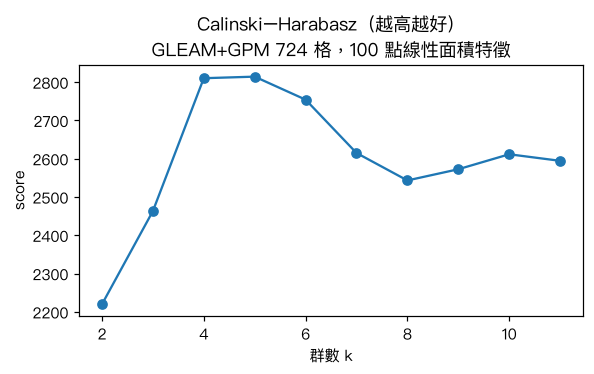

In [4]:
gg_idx100 = np.linspace(0, 999, 100).astype(int)
gg_feat = gg_Ai[:, gg_idx100]                    # 100 點線性面積（deg²）

def gg_agree(lab, ref=gg_group, k=4):
    return max(np.mean(np.array(p)[lab] == ref) for p in permutations(range(k)))

gg_ks = range(2, 12)
gg_ch = [calinski_harabasz_score(gg_feat, KMeans(k, n_init=20, random_state=0).fit_predict(gg_feat)) for k in gg_ks]
gg_km = KMeans(n_clusters=4, n_init=50, random_state=0).fit_predict(gg_feat)

print("CH 分數：")
for k, v in zip(gg_ks, gg_ch):
    print(f"  k = {k:2d}  {v:7,.0f}")
print(f"\nk-means 4 群和固定分群一致的比例: {gg_agree(gg_km)*100:.1f}%")
print("k-means 各群格數（由小到大）:", sorted(np.bincount(gg_km).tolist()))
print("論文固定分群各群格數:        ", [int((gg_group == g).sum()) for g in range(4)])

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(gg_ks, gg_ch, "o-")
ax.set_xlabel("群數 k"); ax.set_ylabel("score")
ax.set_title("Calinski–Harabasz（越高越好）\nGLEAM+GPM 724 格，100 點線性面積特徵")
plt.tight_layout(); plt.show()

## 5. Fig. 2 重現

(a) 把論文的固定分群畫回 1.5° 格子；(b) 曲線，x 是累積貢獻 0–100%，y 是面積（論文標成 10⁴ km²，實際是平方度），0–1000，G4 先畫在最底層。配色取自論文 Fig. 2。

findfont: Failed to find font weight bold for PingFang TC, now using 600.


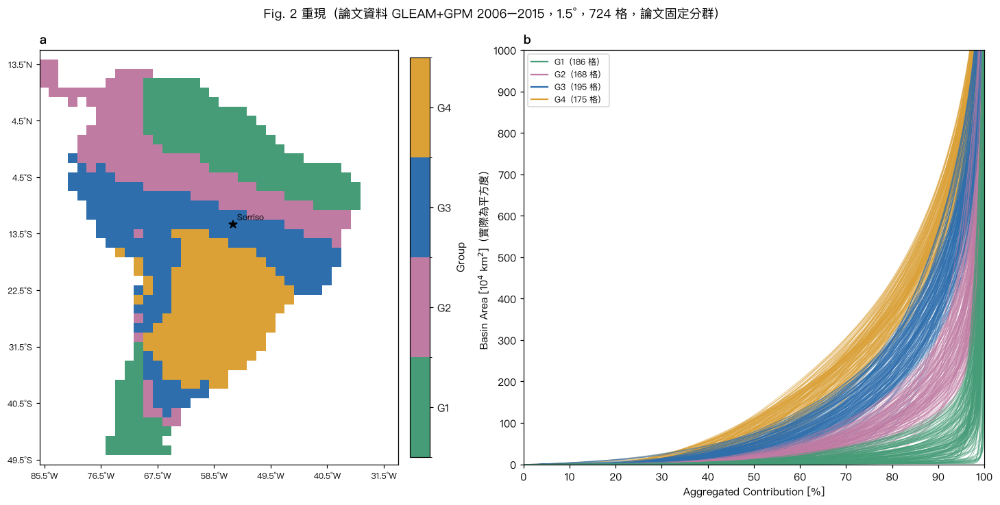

In [5]:
GG_COLORS = ["#459C76", "#C07BA3", "#2E6EAD", "#DBA137"]
gg_cmap = ListedColormap(GG_COLORS); gg_norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), 4)
gg_grid = np.where(gg_fix > 0, gg_fix - 1, np.nan)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 6.8), gridspec_kw={"width_ratios": [1, 1.15]})
pm = axa.pcolormesh(gg_glon, gg_glat, gg_grid, cmap=gg_cmap, norm=gg_norm, shading="nearest")
axa.set_aspect("equal"); axa.set_xlim(-86.25, -29.25); axa.set_ylim(-50.25, 15.75)
axa.set_xticks(np.arange(-85.5, -30, 9)); axa.set_yticks(np.arange(-49.5, 14, 9))
axa.set_xticklabels([f"{-v:g}°W" for v in np.arange(-85.5, -30, 9)], fontsize=8)
axa.set_yticklabels([f"{abs(v):g}°{'S' if v < 0 else 'N'}" for v in np.arange(-49.5, 14, 9)], fontsize=8)
cb = fig.colorbar(pm, ax=axa, ticks=range(4), fraction=0.05, pad=0.03)
cb.ax.set_yticklabels(["G1", "G2", "G3", "G4"]); cb.set_label("Group")
axa.plot(gg_lon[gg_sor], gg_lat[gg_sor], "k*", ms=8)
axa.annotate("Sorriso", (gg_lon[gg_sor], gg_lat[gg_sor]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axa.set_title("a", loc="left", fontweight="bold")

for g in [3, 2, 1, 0]:
    m = gg_group == g
    segs = [np.column_stack([x_, a_]) for x_, a_ in zip(gg_X[m], gg_Ai[m])]
    axb.add_collection(LineCollection(segs, colors=GG_COLORS[g], linewidths=0.6, alpha=0.5))
for g in range(4):
    axb.plot([], [], c=GG_COLORS[g], lw=1.5, label=f"G{g+1}（{(gg_group == g).sum()} 格）")
axb.set_xlim(0, 100); axb.set_ylim(0, 1000)
axb.set_xticks(range(0, 101, 10)); axb.set_yticks(range(0, 1001, 100))
axb.set_xlabel("Aggregated Contribution [%]")
axb.set_ylabel("Basin Area [10$^4$ km$^2$]（實際為平方度）")
axb.legend(loc="upper left", fontsize=8)
axb.set_title("b", loc="left", fontweight="bold")
fig.suptitle("Fig. 2 重現（論文資料 GLEAM+GPM 2006–2015，1.5°，724 格，論文固定分群）")
plt.tight_layout()
plt.savefig(FIG_DIR / "Fig2_GLEAMGPM.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. 轉折點（Fig. 3，原始程式 cell 1、5、12、20）

1. **斜率**：自訂 `slope()`，中間點用前後各隔 2 點的中央差分 $(y_{i+2}-y_{i-2})/(x_{i+2}-x_{i-2})$，兩端改用較短的差分。y 先除以 10（原註解：讓 y 軸和 x 軸的尺度一樣），x 是 %（0–100）。
2. **θ**：`np.arctan(slope) * 180 / np.pi`，單位是度。
3. **θ′**：`np.gradient(θ)`，對陣列索引微分，沒有除以 dx。
4. **平滑**：`medfilt(kernel_size=15)` 後接 `gaussian_filter1d(sigma=10)`。
5. **找峰**：`find_peaks(prominence=0.05)`，取**第一個峰**；找不到峰的曲線不列入。

論文：G1 90–95%、G2 60–75%、G3 40–55%、G4 30–40%，Sorriso 47%。

In [6]:
def gg_slope(x, y):
    s = np.empty(len(x))
    s[0] = (y[1] - y[0]) / (x[1] - x[0])
    s[1] = (y[2] - y[0]) / (x[2] - x[0])
    s[-2] = (y[-1] - y[-3]) / (x[-1] - x[-3])
    s[-1] = (y[-1] - y[-2]) / (x[-1] - x[-2])
    s[2:-2] = (y[4:] - y[:-4]) / (x[4:] - x[:-4])
    return s

def gg_turning(x, y):
    theta = np.degrees(np.arctan(gg_slope(x, y / 10)))
    r = gaussian_filter1d(medfilt(np.gradient(theta), kernel_size=15), sigma=10)
    peaks, _ = find_peaks(r, prominence=0.05)
    return r, x[peaks]

gg_res = [gg_turning(x, y) for x, y in zip(gg_X, gg_Ai)]
gg_r = np.array([r for r, _ in gg_res])
gg_peaks = [p for _, p in gg_res]
gg_tp = np.array([p[0] if len(p) else np.nan for p in gg_peaks])          # 第一個峰
gg_npk = np.array([len(p) for p in gg_peaks])

paper = ["90–95", "60–75", "40–55", "30–40"]
print("        論文     中位數   平均    Q1–Q3          無峰  峰數≥3")
for g in range(4):
    m = gg_group == g; v = gg_tp[m]
    print(f"G{g+1}  {paper[g]:>7}  {np.nanmedian(v):7.1f}  {np.nanmean(v):6.1f}  "
          f"{np.nanpercentile(v, 25):5.1f}–{np.nanpercentile(v, 75):5.1f}  {np.isnan(v).sum():6d}  {(gg_npk[m] >= 3).sum():6d}")
print(f"\nSorriso：轉折點 {gg_tp[gg_sor]:.1f}%（論文 47%），對應面積 {np.interp(gg_tp[gg_sor], gg_X[gg_sor], gg_Ai[gg_sor]):.0f} deg²")

        論文     中位數   平均    Q1–Q3          無峰  峰數≥3
G1    90–95     95.3    92.7   91.3– 96.9       5      15
G2    60–75     68.6    69.8   60.6– 79.2       0      87
G3    40–55     48.0    49.4   38.1– 58.7       0     109
G4    30–40     35.5    35.8   29.6– 42.8       0      70

Sorriso：轉折點 46.7%（論文 47%），對應面積 35 deg²


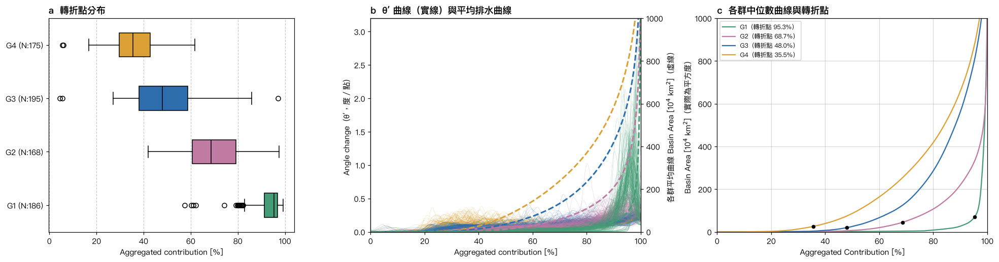

In [7]:
fig, (axa, axb, axc) = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})

# (a) 各群第一個峰的箱形圖（論文 Fig. 3a，原始程式 cell 12）
data = [gg_tp[(gg_group == g) & ~np.isnan(gg_tp)] for g in range(4)]
box = axa.boxplot(data, orientation="horizontal", patch_artist=True)
for patch, c in zip(box["boxes"], GG_COLORS):
    patch.set_facecolor(c)
for med in box["medians"]:
    med.set_color("black")
axa.set_yticks(range(1, 5)); axa.set_yticklabels([f"G{g+1} (N:{(gg_group == g).sum()})" for g in range(4)])
axa.set_xlabel("Aggregated contribution [%]"); axa.grid(axis="x", ls="--", alpha=0.7)
axa.set_title("a  轉折點分布", loc="left", fontweight="bold")

# (b) 各群 θ′ 曲線（論文 Fig. 3b，原始程式 cell 7–10）與各群平均曲線（右軸）
axb2 = axb.twinx()
for g in [3, 2, 1, 0]:
    m = gg_group == g
    for x_, r_ in zip(gg_X[m], gg_r[m]):
        axb.plot(x_, r_, c=GG_COLORS[g], lw=0.3, alpha=0.4)
    axb2.plot(gg_con[m].mean(0), gg_area[m].mean(0), c=GG_COLORS[g], lw=2, ls="--")
axb.set_xlim(0, 100); axb.set_ylim(0, 3.2)
axb.set_xlabel("Aggregated contribution [%]"); axb.set_ylabel("Angle change（θ′，度／點）")
axb2.set_ylim(0, 1000); axb2.set_ylabel("各群平均曲線 Basin Area [10$^4$ km$^2$]（虛線）")
axb.set_title("b  θ′ 曲線（實線）與平均排水曲線", loc="left", fontweight="bold")

# (c) 各群轉折點最接近中位數的那條曲線與轉折點（論文 Fig. S5，原始程式 cell 20）
for g in range(4):
    m = np.nonzero((gg_group == g) & ~np.isnan(gg_tp))[0]
    med = np.nanmedian(gg_tp[m])
    k = m[np.argmin(np.abs(gg_tp[m] - med))]          # 轉折點最接近該群中位數的那條曲線
    axc.plot(gg_X[k], gg_Ai[k], c=GG_COLORS[g], lw=1.5, label=f"G{g+1}（轉折點 {gg_tp[k]:.1f}%）")
    axc.plot(gg_tp[k], np.interp(gg_tp[k], gg_X[k], gg_Ai[k]), "ko", ms=4)
axc.set_xlim(0, 100); axc.set_ylim(0, 1000)
axc.set_xlabel("Aggregated Contribution [%]"); axc.set_ylabel("Basin Area [10$^4$ km$^2$]（實際為平方度）")
axc.legend(fontsize=8); axc.grid(alpha=0.5)
axc.set_title("c  各群中位數曲線與轉折點", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "Fig3_GLEAMGPM.png", dpi=200, bbox_inches="tight")
plt.show()

## 附錄：之前的做法錯在哪

這本筆記本之前還有一大段用 ERA5 資料、照論文文字猜測細節的分析（完整舊版備份在 `_backup/Reproduce_before_cleanup.ipynb`）。拿到作者的原始程式和 pversion 資料後，對照出下面這些差別。

### (a) 資料

**ERA5 的三個 nc 檔不是論文的資料**

| | 論文 | `data/drainage_curves_*.nc` |
|---|---|---|
| 驅動資料 | GPM IMERG 降雨、GLEAM v3.6a 蒸發、ERA-Interim 風與濕度 | ERA5 |
| 期間 | 2006–2015 | 2020–2025 |
| 解析度 | 1.5°，南美 724 格 | 0.25°，南美約 2.5 萬格 |
| 追蹤範圍 | 只有南美（30°W–85.5°W、15°N–49.5°S） | 全球 |
| 面積單位 | 平方度（格數 × 2.25） | km²，依緯度計算 |
| 曲線尾巴 | 最多 1629 deg² | C 接近 100% 時達 10⁷–10⁸ km² |

所以 ERA5 版的分群和轉折點本來就對不上論文：線性面積特徵會被超長的尾巴主導，CH 最高落在 k = 3 或 5，地圖上論文的 G3 會整群併進 G4。

**兩版 con 檔**：`data/gleamgpm_0615_allpoint_con.npy` 和論文用的 `Original_code_from_authors/gleamgpm_0615_pversion_allpoint_con.npy` 的 area 完全相同，但 con 每一列都不同。用 data/ 版跑同樣的算法：

| | pversion（論文） | data/ 版 |
|---|---|---|
| 第 1 個來源格點佔比（中位數） | 30.3% | 10.2% |
| 有效來源格點數（中位數） | 10 | 51 |
| k-means 和固定分群一致 | 96.0% | 83.3% |
| CH 最高 | k = 5（和 k = 4 只差 0.1%） | k = 6 |
| 轉折點中位數 G1 / G2 / G3 / G4 | 95.3 / 68.6 / 48.0 / 35.5% | 89.5 / 49.3 / 23.0 / 3.6% |

**pversion 是什麼**

- 文件裡寫的：論文正文和補充材料都沒有提到兩個版本的 con，也沒有說明 pversion。原始程式只在 cell 3 第 2–3 行讀了 pversion 檔，沒有註解。
- 從數據確定的：兩版都是貢獻由大到小排序。pversion 的貢獻更集中在前幾個來源，99.7% 的數值 pversion ≥ data/ 版。它不是同一組貢獻換排序，也不是取某個次方，也不是多插入一個來源（例如局地再循環）。
- 推測：pversion 可能是用不同的方式算每個來源格點的貢獻（權重或分母不同，「p」也許是 precipitation），或是不同版本的追蹤設定。需要問作者。可以確定的是，論文發表的轉折點和分群都只有用 pversion 才重現得出來。

### (b) 轉折點算法

| 步驟 | 作者原始程式（本筆記本） | 之前的猜測 |
|---|---|---|
| 軸的尺度 | x = %（0–100），y = 平方度 ÷ 10 | 每條曲線各自縮放到 0–1，或用 10⁴ / 10⁵ km² |
| 斜率 | 前後各隔 2 點的中央差分，兩端另外處理 | `np.gradient` |
| θ 單位 | 度 | 弧度 |
| θ′ | `np.gradient(θ)`，對索引，不除以 dx | 除以 dx（每 %），所以同樣的 0.05 門檻意義差約 5–6 倍 |
| 平滑 | 對 θ′：`medfilt(15)` 再 `gaussian_filter1d(σ=10)` | 對曲線 y：只有高斯 σ = 10 |
| 找峰 | `find_peaks(prominence=0.05)`，不設 distance | 另外加了 distance = 10% C（照 Methods 文字） |
| 取峰 | 第一個峰 | 第一個峰和最大峰都試過 |

每條曲線各自縮放到 0–1 時，所有曲線形狀變得很像，最大峰全落在 85–95%，排不出 G1 > G2 > G3 > G4。

### (c) k-means 特徵：線性 vs log

| 特徵（pversion） | 和固定分群一致 | CH 最高 |
|---|---|---|
| 100 點線性面積，不標準化 | 96.0% | k = 5（≈ k = 4） |
| 100 點 log10 面積 | 60.1% | k = 5 |

論文 Methods 沒寫要不要取 log，正確的是線性面積。

### (d) ln 取在哪一軸

Supp D 的文字寫「對 CDF 取 ln」，所以之前把 ln 放在累積貢獻 C 上；原始程式其實是 ln(面積 + 0.225) 對 C 線性內插。對分群影響很小（之前用 ERA5 比較，只有 0.3% 的格點換群），但會影響曲線前段形狀和轉折點。

### (e) 經緯度

拿到 `group_fix_4groups.txt` 之前，是用 ERA5 曲線加動態規劃猜 724 列各在哪一格：選出的格子有 710 / 724 和正確的一樣，但順序錯位，只有 322 列真的對到正確位置，所以當時的地圖有不少位移。現在直接用作者的檔案。

## 7. 用作者的算法跑 ERA5（2020–2025）

把第 3、4、6 節**作者的算法**原樣套到 `data/drainage_curves_land.nc`（ERA5 2020–2025、0.25°、WAM-2layers v3、只算陸地來源）。

| | 作者（GLEAM+GPM 2006–2015） | ERA5 nc（2020–2025） | 這裡怎麼處理 |
|---|---|---|---|
| 格點 | 1.5°，724 格 | 0.25°，全球 42 個 AR6 區域、185,546 格 | 和論文比時，**用 1.5° 格子裡全部的 0.25° 格點**（約 36 個），不用單一中心點 |
| 面積單位 | 平方度（格數 × 2.25） | km² | **km² ÷ 12,364**（赤道 1 deg² 的面積）換成「等效平方度」 |
| 曲線的點 | 725 點，C 從 0 到 100% | 199 個 level，C = 0.5%–99.5% | x = level × 100，照原樣用 |
| 來源範圍 | 只有南美框內 724 格陸地，分母只算它們 | 各 AR6 區域各跑一組，來源範圍大很多 | 不截斷（nc 只有建好的曲線，無法拿掉框外來源） |

**重要**：單一 0.25° 格點不能代表論文的 1.5° 格子（約 2.7 萬 km² vs 750 km²）。和論文比較時，一律用整個 1.5° 格子裡的全部 0.25° 格點（分群後用多數決、或取中位數合併回 1.5°）。

### 7.1 建曲線（全部陸地格點）

所有曲線的 x 都一樣，內插用向量化計算（和第 3 節的 `gg_interp` 相同：ln(面積 + a) 對 x 線性內插 1000 點，a = 最小正面積 ÷ 10），只保留 100 點特徵和 C = 50% 的面積 A50；轉折點用第 6 節的 `gg_turning` 逐條計算。每個 0.25° 格點也記下它落在論文哪一個 1.5° 格子。

**面積的 cos 緯度校正**：作者的面積是「格數 × 2.25」，每個 1.5° 格子不論緯度都算 2.25 平方度；ERA5 的 `area_at_level` 是真實面積（km²），高緯度的格子比較小（面積 ∝ cos 緯度，見 `Mongolia/DENSITY.md`：0.25° 格子在赤道 773 km²、50° 497 km²）。為了讓 ERA5 的單位接近作者的「格數平方度」，每條曲線的面積除以**目標格點緯度上 1 平方度的面積**：

$$A_{1°×1°}(\varphi) = R^2\,\Delta\lambda\,\big(\sin(\varphi+0.5°)-\sin(\varphi-0.5°)\big) \approx 12{,}364\cos\varphi\ \text{km}^2,\quad R = 6371.0088\ \text{km}$$

這是**近似**：曲線裡的來源格點分布在各個緯度，不一定和目標格點同緯度，這裡用目標格點的緯度代表整條曲線。沒有校正的版本（km² ÷ 12,364，赤道等效平方度）也算一份（`gl_feat_nc` 等），最後的總表會比較兩者。

In [8]:
import xarray as xr
import time
from scipy.stats import spearmanr

E5_SA = ["NWS", "NSA", "SAM", "NES", "SWS", "SES", "SSA"]
e5_ds = xr.open_dataset("../data/drainage_curves_land.nc")
gl_lat, gl_lon, gl_rg = e5_ds.tag_lat.values, e5_ds.tag_lon.values, e5_ds.run_group.values
gl_n = len(gl_lat)
gl_sa = np.isin(gl_rg, E5_SA)

_t0 = time.time()
gl_x = e5_ds.level.values * 100
gl_X = np.linspace(gl_x.min(), gl_x.max(), 1000)
_j = np.clip(np.searchsorted(gl_x, gl_X) - 1, 0, len(gl_x) - 2)
_w = (gl_X - gl_x[_j]) / (gl_x[_j + 1] - gl_x[_j])
gl_i50 = np.argmin(np.abs(gl_X - 50))
# 面積換算成「作者式的平方度」：km² ÷（目標格點緯度上 1 平方度的面積）
# 1°×1° 格子的面積 = R² · Δλ · (sin(φ+0.5°) − sin(φ−0.5°))，和 Mongolia/DENSITY.md 的 cell_area 同一個公式（∝ cos φ）
E5_R = 6371.0088                                                       # km，地球平均半徑
def e5_deg2_km2(lat):
    return E5_R ** 2 * np.deg2rad(1.0) * (np.sin(np.deg2rad(lat + 0.5)) - np.sin(np.deg2rad(lat - 0.5)))
gl_coslat = e5_deg2_km2(gl_lat) / e5_deg2_km2(0.0)                     # ≈ cos(緯度)

def e5_build(divisor):
    feat = np.empty((gl_n, 100), np.float32); a50 = np.empty(gl_n, np.float32); tp = np.full(gl_n, np.nan, np.float32)
    for s in range(0, gl_n, 20000):
        y = e5_ds.area_at_level.values[s:s + 20000] / divisor[s:s + 20000, None]
        a = np.where(y > 0, y, np.inf).min(1, keepdims=True) / 10
        L = np.log(y + a)
        Ai = np.exp(L[:, _j] * (1 - _w) + L[:, _j + 1] * _w) - a
        feat[s:s + 20000] = Ai[:, gg_idx100]
        a50[s:s + 20000] = Ai[:, gl_i50]
        tp[s:s + 20000] = [(lambda p: p[0] if len(p) else np.nan)(gg_turning(gl_X, r)[1]) for r in Ai]
    return feat, a50, tp

# 主要：cos 緯度校正（作者式平方度）
gl_feat, gl_a50, gl_tp = e5_build(e5_deg2_km2(gl_lat))
# 對照：沒有校正（赤道等效平方度，km² ÷ 12,364）
gl_feat_nc, gl_a50_nc, gl_tp_nc = e5_build(np.full(gl_n, e5_deg2_km2(0.0)))
print(f"1 平方度的面積：赤道 {e5_deg2_km2(0):,.0f} km²，30° {e5_deg2_km2(30):,.0f}，50° {e5_deg2_km2(50):,.0f}，60° {e5_deg2_km2(60):,.0f}")
print(f"{gl_n} 條曲線（{len(np.unique(gl_rg))} 個 AR6 區域），兩種單位的內插＋轉折點共耗時 {time.time() - _t0:.0f} 秒")
print(f"南美 7 區：{gl_sa.sum()} 格")

# 每個 0.25° 格點落在論文哪個 1.5° 格子（-1 = 不在論文 724 格內）
gl_I = np.round((gg_glat[0] - gl_lat) / 1.5).astype(int)
gl_J = np.round((gl_lon - gg_glon[0]) / 1.5).astype(int)
_ok = (gl_I >= 0) & (gl_I < 44) & (gl_J >= 0) & (gl_J < 38)
gl_paper = np.full(gl_n, -1)
gl_paper[_ok] = gg_fix[gl_I[_ok], gl_J[_ok]].astype(int) - 1
gl_box = np.full(gl_n, -1)                                     # 對應到論文第幾列（0–723）
_pos = {(i, j): k for k, (i, j) in enumerate(zip(gg_ii, gg_jj))}
for k in np.nonzero(gl_paper >= 0)[0]:
    gl_box[k] = _pos[(gl_I[k], gl_J[k])]
print(f"落在論文 724 個 1.5° 格子裡的 0.25° 格點：{(gl_box >= 0).sum()}（涵蓋 {len(np.unique(gl_box[gl_box >= 0]))} / 724 格）")

def e5_vote(labels, mask):
    # 把 0.25° 標籤用多數決合併回論文 724 格；沒有 0.25° 格點的格子為 −1
    out = np.full(len(gg_group), -1)
    m = mask & (gl_box >= 0)
    for k in np.unique(gl_box[m]):
        out[k] = np.bincount(labels[m & (gl_box == k)], minlength=4).argmax()
    return out
def e5_mapax(ax, title):
    ax.set_aspect("equal"); ax.set_xlim(-86.25, -29.25); ax.set_ylim(-56.5, 15.75)
    ax.set_xticks(np.arange(-85.5, -30, 9)); ax.set_yticks(np.arange(-49.5, 14, 9))
    ax.set_xticklabels([f"{-v:g}°W" for v in np.arange(-85.5, -30, 9)], fontsize=8)
    ax.set_yticklabels([f"{abs(v):g}°{'S' if v < 0 else 'N'}" for v in np.arange(-49.5, 14, 9)], fontsize=8)
    ax.set_title(title, loc="left", fontweight="bold")


1 平方度的面積：赤道 12,364 km²，30° 10,708，50° 7,948，60° 6,182
185546 條曲線（42 個 AR6 區域），兩種單位的內插＋轉折點共耗時 41 秒
南美 7 區：24734 格
落在論文 724 個 1.5° 格子裡的 0.25° 格點：24299（涵蓋 724 / 724 格）


### 7.2 逐格比較曲線（不靠分群）

每個論文 1.5° 格子，取裡面全部 0.25° 格點 A50（達到 C = 50% 需要的面積）的中位數，和作者資料同一格的 A50 比。兩邊都用「作者式平方度 × 111.2² km²」換成 10⁴ km²（ERA5 已做 cos 緯度校正）。

有 ERA5 格點的論文格子：724 / 724
逐格 A50：Spearman ρ = 0.66；ERA5 ÷ 作者 中位數 3.83（Q1–Q3 2.20–6.17）
log10(A50) 的格點間標準差：作者 0.59，ERA5 0.43

依論文分群的 A50 中位數（10⁴ km²）：
  G1  作者    4.1   ERA5   45.6   放大 11.3 倍
  G2  作者   17.4   ERA5   83.3   放大 4.8 倍
  G3  作者   46.5   ERA5  135.6   放大 2.9 倍
  G4  作者   96.1   ERA5  239.1   放大 2.5 倍
G4 ÷ G1：作者 23.7 倍，ERA5 5.2 倍


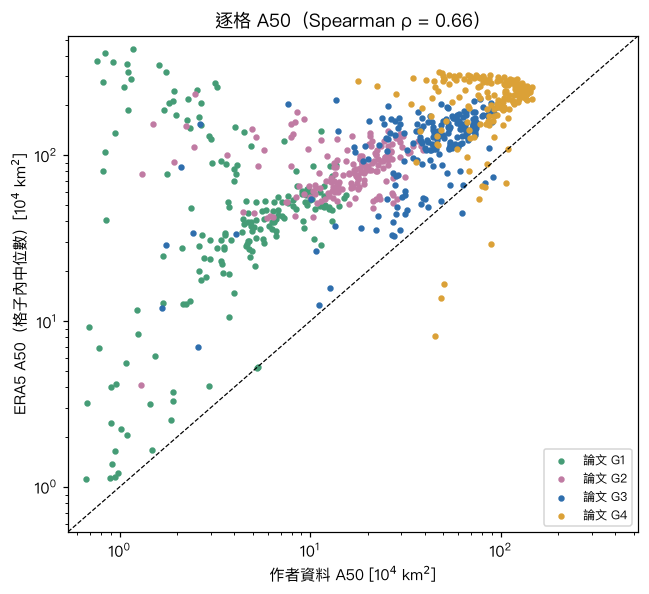

In [9]:
_auth = np.array([np.interp(50, x, y) for x, y in zip(gg_X, gg_Ai)]) * 111.2 ** 2 / 1e4
_era = np.full(len(gg_group), np.nan)
for k in np.unique(gl_box[gl_box >= 0]):
    _era[k] = np.median(gl_a50[gl_box == k]) * 111.2 ** 2 / 1e4      # 作者式平方度 → 和作者同樣的換算
_ok = ~np.isnan(_era) & (_auth > 0)
e5_rho = spearmanr(_auth[_ok], _era[_ok])[0]
_ratio = _era[_ok] / _auth[_ok]
print(f"有 ERA5 格點的論文格子：{_ok.sum()} / 724")
print(f"逐格 A50：Spearman ρ = {e5_rho:.2f}；ERA5 ÷ 作者 中位數 {np.median(_ratio):.2f}（Q1–Q3 {np.percentile(_ratio, 25):.2f}–{np.percentile(_ratio, 75):.2f}）")
print(f"log10(A50) 的格點間標準差：作者 {np.log10(_auth[_ok]).std():.2f}，ERA5 {np.log10(_era[_ok]).std():.2f}")
print("\n依論文分群的 A50 中位數（10⁴ km²）：")
for g in range(4):
    m = _ok & (gg_group == g)
    print(f"  G{g+1}  作者 {np.median(_auth[m]):6.1f}   ERA5 {np.median(_era[m]):6.1f}   放大 {np.median(_era[m]) / np.median(_auth[m]):.1f} 倍")
_ma = [np.median(_auth[_ok & (gg_group == g)]) for g in range(4)]; _me = [np.median(_era[_ok & (gg_group == g)]) for g in range(4)]
print(f"G4 ÷ G1：作者 {_ma[3] / _ma[0]:.1f} 倍，ERA5 {_me[3] / _me[0]:.1f} 倍")

fig, ax = plt.subplots(figsize=(6, 5.5))
for g in range(4):
    m = _ok & (gg_group == g)
    ax.scatter(_auth[m], _era[m], s=10, c=GG_COLORS[g], label=f"論文 G{g+1}")
_lim = [min(_auth[_ok].min(), _era[_ok].min()) * 0.8, max(_auth[_ok].max(), _era[_ok].max()) * 1.2]
ax.plot(_lim, _lim, "k--", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(_lim); ax.set_ylim(_lim)
ax.set_xlabel("作者資料 A50 [10$^4$ km$^2$]"); ax.set_ylabel("ERA5 A50（格子內中位數）[10$^4$ km$^2$]")
ax.legend(fontsize=8); ax.set_title(f"逐格 A50（Spearman ρ = {e5_rho:.2f}）")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_A50_scatter.png", dpi=200, bbox_inches="tight"); plt.show()

### 7.3 南美 7 區全部格點分群

用南美洲 7 個 AR6 區域（NWS、NSA、SAM、NES、SWS、SES、SSA）的**全部 0.25° 格點**一起分 k = 4：CH 測 k = 2–11，k-means 4 群（`n_init=50, random_state=0`），依 C = 50% 面積中位數命名 G1–G4。和論文比較時：(1) 每個 0.25° 格點對到它所在的論文 1.5° 格子比；(2) 每個 1.5° 格子裡的 0.25° 標籤用多數決合併後比。

In [10]:
sa_i = np.nonzero(gl_sa)[0]
sa_feat, sa_a50 = gl_feat[sa_i], gl_a50[sa_i]
sa_ch = [calinski_harabasz_score(sa_feat, KMeans(k, n_init=10, random_state=0).fit_predict(sa_feat)) for k in gg_ks]
print("CH：" + "  ".join(f"k={k}:{v:,.0f}" for k, v in zip(gg_ks, sa_ch)) + f"\nCH 最高：k = {list(gg_ks)[int(np.argmax(sa_ch))]}")

_lab = KMeans(n_clusters=4, n_init=50, random_state=0).fit_predict(sa_feat)
_med = [np.median(sa_a50[_lab == g]) for g in range(4)]
_rank = np.empty(4, int); _rank[np.argsort(_med)] = np.arange(4)
gl_sagroup = np.full(gl_n, -1); gl_sagroup[sa_i] = _rank[_lab]
sa_group = gl_sagroup[sa_i]
print("\n        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）")
for g in range(4):
    m = sa_group == g; t = gl_tp[sa_i][m]
    print(f"G{g+1}   {m.sum():6d} ({m.mean()*100:4.1f}%)      {np.median(sa_a50[m]):6.0f}                  "
          f"{np.nanmedian(t):5.1f} ({np.nanpercentile(t, 25):.1f}–{np.nanpercentile(t, 75):.1f})")
print("論文各群比例：" + "  ".join(f"G{g+1} {(gg_group == g).mean()*100:.1f}%" for g in range(4)))

_m = gl_sa & (gl_paper >= 0)
cm = np.array([[np.sum((gl_paper[_m] == a) & (gl_sagroup[_m] == b)) for b in range(4)] for a in range(4)])
print(f"\n(1) 0.25° 逐格（{_m.sum()} 格）：同名一致 {np.mean(gl_sagroup[_m] == gl_paper[_m])*100:.1f}%，最佳標籤對應 {gg_agree(gl_sagroup[_m], gl_paper[_m])*100:.1f}%")
print("    混淆矩陣（列 = 論文 G，欄 = ERA5 G）")
for a in range(4):
    print(f"    論文G{a+1}" + "".join(f"{v:8d}" for v in cm[a]))
sa_vote = e5_vote(gl_sagroup, gl_sa)
_v = sa_vote >= 0
cmv = np.array([[np.sum((gg_group[_v] == a) & (sa_vote[_v] == b)) for b in range(4)] for a in range(4)])
print(f"\n(2) 多數決合併到 1.5°（{_v.sum()} 格）：同名一致 {np.mean(sa_vote[_v] == gg_group[_v])*100:.1f}%，最佳標籤對應 {gg_agree(sa_vote[_v], gg_group[_v])*100:.1f}%")
for a in range(4):
    print(f"    論文G{a+1}" + "".join(f"{v:6d}" for v in cmv[a]))

print("\n轉折點中位數，依論文分群（每格取裡面全部 0.25° 格點）：")
for g in range(4):
    t = gl_tp[gl_sa & (gl_paper == g)]
    print(f"  G{g+1}  ERA5 {np.nanmedian(t):5.1f}%（{np.nanpercentile(t, 25):.1f}–{np.nanpercentile(t, 75):.1f}）   GLEAM {np.nanmedian(gg_tp[gg_group == g]):5.1f}%   論文 {paper[g]}")

CH：k=2:20,454  k=3:18,692  k=4:21,055  k=5:21,984  k=6:21,756  k=7:21,359  k=8:21,167  k=9:20,751  k=10:20,219  k=11:19,938
CH 最高：k = 5



        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）
G1     3819 (15.4%)          25                   79.2 (71.6–84.9)
G2     2056 ( 8.3%)          55                   48.4 (34.2–61.1)
G3     8536 (34.5%)          57                   78.7 (71.1–83.0)
G4    10323 (41.7%)         154                   89.9 (25.2–94.7)
論文各群比例：G1 25.7%  G2 23.2%  G3 26.9%  G4 24.2%

(1) 0.25° 逐格（24020 格）：同名一致 36.3%，最佳標籤對應 54.8%
    混淆矩陣（列 = 論文 G，欄 = ERA5 G）
    論文G1    1472    1796    2672     123
    論文G2     293     249    4428     297
    論文G3    1251       0    1302    4132
    論文G4     315       0       0    5690

(2) 多數決合併到 1.5°（713 格）：同名一致 36.2%，最佳標籤對應 55.0%
    論文G1    44    60    76     6
    論文G2    10    11   127     9
    論文G3    39     0    37   119
    論文G4     9     0     0   166

轉折點中位數，依論文分群（每格取裡面全部 0.25° 格點）：
  G1  ERA5  65.4%（51.8–74.5）   GLEAM  95.3%   論文 90–95
  G2  ERA5  79.9%（76.9–84.0）   GLEAM  68.6%   論文 60–75
  G3  ERA5  86.6%（73.5–90.9）   GLEAM  48.0%   論文 40–55
  G4  ER

ERA5 南美 7 區全部格點（24,734 格）
  k = 2  CH =   20,454
  k = 3  CH =   18,692
  k = 4  CH =   21,055   ← 論文用的 k
  k = 5  CH =   21,984   ← 最高
  k = 6  CH =   21,756
  k = 7  CH =   21,359
  k = 8  CH =   21,167
  k = 9  CH =   20,751
  k = 4 比最高（k = 5）低 4.2%

作者資料 GLEAM+GPM pversion（724 格）
  k = 2  CH =    2,220
  k = 3  CH =    2,463
  k = 4  CH =    2,810   ← 論文用的 k
  k = 5  CH =    2,814   ← 最高
  k = 6  CH =    2,754
  k = 7  CH =    2,615
  k = 8  CH =    2,543
  k = 9  CH =    2,572
  k = 4 比最高（k = 5）低 0.1%



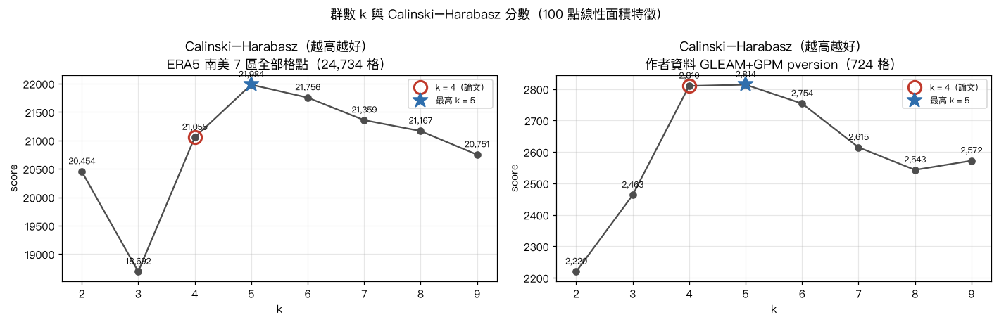

In [11]:
# CH 分數 k = 2–9：ERA5 南美 7 區全部格點（本節），和作者資料（第 4 節，同樣是 100 點線性面積）並排
_ks = np.arange(2, 10)
_sets = [("ERA5 南美 7 區全部格點（24,734 格）", np.array(sa_ch)[: len(_ks)]),
         ("作者資料 GLEAM+GPM pversion（724 格）", np.array(gg_ch)[: len(_ks)])]
for name, ch in _sets:
    best = _ks[np.argmax(ch)]
    print(name)
    for k, v in zip(_ks, ch):
        print(f"  k = {k}  CH = {v:8,.0f}" + ("   ← 最高" if k == best else "") + ("   ← 論文用的 k" if k == 4 else ""))
    print(f"  k = 4 比最高（k = {best}）低 {(1 - ch[2] / ch.max()) * 100:.1f}%\n")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (name, ch) in zip(axs, _sets):
    best = _ks[np.argmax(ch)]
    ax.plot(_ks, ch, "o-", c="0.3")
    ax.plot(4, ch[2], "o", ms=12, mfc="none", mec="#C0392B", mew=2, label="k = 4（論文）")
    ax.plot(best, ch.max(), "*", ms=15, c="#2E6EAD", label=f"最高 k = {best}")
    for k, v in zip(_ks, ch):
        ax.annotate(f"{v:,.0f}", (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_xticks(_ks); ax.set_xlabel("k"); ax.set_ylabel("score")
    ax.set_title(f"Calinski–Harabasz（越高越好）\n{name}"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle("群數 k 與 Calinski–Harabasz 分數（100 點線性面積特徵）")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_CH_ERA5_SA7.png", dpi=200, bbox_inches="tight"); plt.show()

#### Davies–Bouldin 指數：另一個選 k 的指標

**定義**：對每一群 $i$，算群內離散 $s_i$（群內各點到重心的平均距離），再和其他每一群 $j$ 比較 $R_{ij} = (s_i + s_j) / d_{ij}$（$d_{ij}$ 是兩群重心的距離），取最大的 $R_{ij}$，最後對所有群平均：

$$DB = \frac{1}{k}\sum_{i=1}^{k}\max_{j\neq i}\frac{s_i + s_j}{d_{ij}}$$

DB **越低越好**（群內越緊、群間越開）；CH 則是越高越好。兩者的分子分母角色相反，但都只用到各點到重心、以及重心之間的距離。

**計算成本**：分群標籤給定之後，DB 和 CH 一樣只需要每個點到自己重心的距離，約 $O(N\cdot k\cdot d)$（$N$ 格點數、$d$ = 100 維特徵），所以真正花時間的是 k-means 本身；silhouette 係數要算所有點兩兩的距離，約 $O(N^2)$，在 24,734 格時就很昂貴。

這裡用和 CH 一樣的 k-means 設定重新分群（ERA5 南美 7 區：`KMeans(k, n_init=10, random_state=0)`；作者資料：`KMeans(k, n_init=20, random_state=0)`），算 `sklearn.metrics.davies_bouldin_score`，和 CH 並排畫圖。

ERA5 南美 7 區（24,734 格，cos 校正）
  k     CH          DB
  2     20,454    0.760   ← DB 最低
  3     18,692    0.893
  4     21,055    0.882
  5     21,984    0.884   ← CH 最高
  6     21,756    0.906
  7     21,359    0.928
  8     21,167    0.944
  9     20,751    0.977
  CH 最佳 k = 5，DB 最佳 k = 2；k = 4 的 DB = 0.882

作者資料 GLEAM+GPM pversion（724 格）
  k     CH          DB
  2      2,220    0.512   ← DB 最低
  3      2,463    0.605
  4      2,810    0.619
  5      2,814    0.707   ← CH 最高
  6      2,754    0.757
  7      2,615    0.803
  8      2,543    0.870
  9      2,572    0.822
  CH 最佳 k = 5，DB 最佳 k = 2；k = 4 的 DB = 0.619



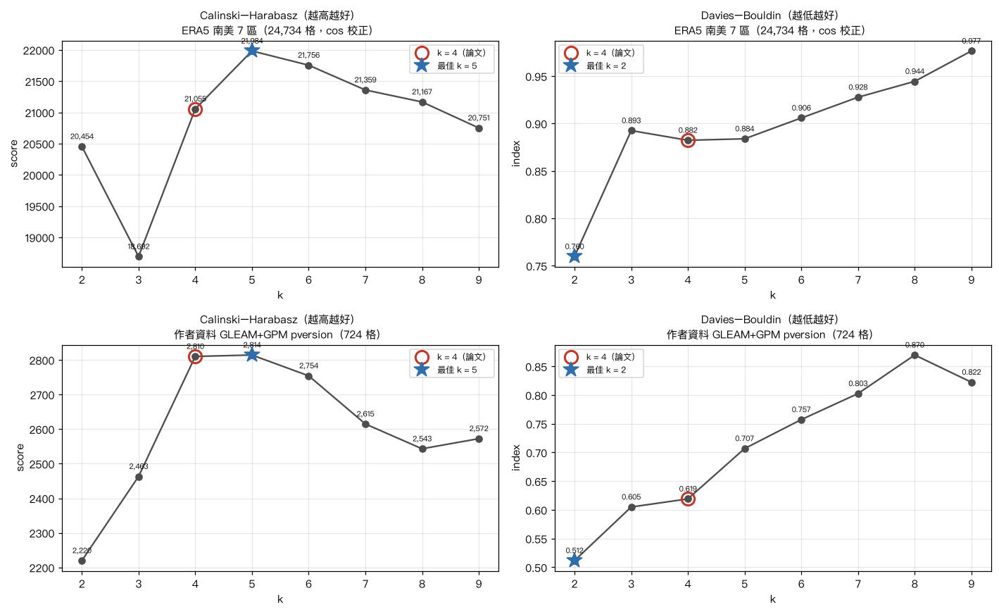

In [12]:
from sklearn.metrics import davies_bouldin_score

_ks = np.arange(2, 10)
db_sa = np.array([davies_bouldin_score(sa_feat, KMeans(k, n_init=10, random_state=0).fit_predict(sa_feat)) for k in _ks])
db_gg = np.array([davies_bouldin_score(gg_feat, KMeans(k, n_init=20, random_state=0).fit_predict(gg_feat)) for k in _ks])
_rows = [("ERA5 南美 7 區（24,734 格，cos 校正）", np.array(sa_ch)[:8], db_sa),
         ("作者資料 GLEAM+GPM pversion（724 格）", np.array(gg_ch)[:8], db_gg)]
for name, ch, db in _rows:
    print(name)
    print("  k     CH          DB")
    for k, c, d in zip(_ks, ch, db):
        print(f"  {k}  {c:9,.0f}   {d:6.3f}" + ("   ← CH 最高" if c == ch.max() else "") + ("   ← DB 最低" if d == db.min() else ""))
    print(f"  CH 最佳 k = {_ks[np.argmax(ch)]}，DB 最佳 k = {_ks[np.argmin(db)]}；k = 4 的 DB = {db[2]:.3f}\n")

fig, axs = plt.subplots(2, 2, figsize=(13, 8))
for r, (name, ch, db) in enumerate(_rows):
    for c, (vals, lab, ylab, best_k, fmt) in enumerate([(ch, "Calinski–Harabasz（越高越好）", "score", _ks[np.argmax(ch)], "{:,.0f}"),
                                                          (db, "Davies–Bouldin（越低越好）", "index", _ks[np.argmin(db)], "{:.3f}")]):
        ax = axs[r, c]
        ax.plot(_ks, vals, "o-", c="0.3")
        ax.plot(4, vals[2], "o", ms=12, mfc="none", mec="#C0392B", mew=2, label="k = 4（論文）")
        ax.plot(best_k, vals[list(_ks).index(best_k)], "*", ms=15, c="#2E6EAD", label=f"最佳 k = {best_k}")
        for k, v in zip(_ks, vals):
            ax.annotate(fmt.format(v), (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
        ax.set_xticks(_ks); ax.set_xlabel("k"); ax.set_ylabel(ylab)
        ax.set_title(f"{lab}\n{name}", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_DB_ERA5_SA7.png", dpi=200, bbox_inches="tight"); plt.show()

**結果**：兩份資料的 DB 都在 **k = 2 最低**（ERA5 0.760、作者資料 0.512），之後大致隨 k 變大而升高；CH 則兩份都在 k = 5 最高、k = 4 幾乎一樣。k = 4 的 DB：ERA5 0.882（和 k = 3、5 差不多）、作者資料 0.619（只比 k = 3 的 0.605 稍高）。

DB 偏好 k = 2，常見原因是它看「最相似的那一對群」：群越多，總會有兩群靠得比較近，DB 就變差；資料若是連續分布、沒有明顯的群，DB 通常會一路往 k = 2 靠。所以 DB 和 CH 都**沒有**明確指向 k = 4，論文選 4 群比較像是「可解釋性」上的選擇，而不是指標上的最佳值。

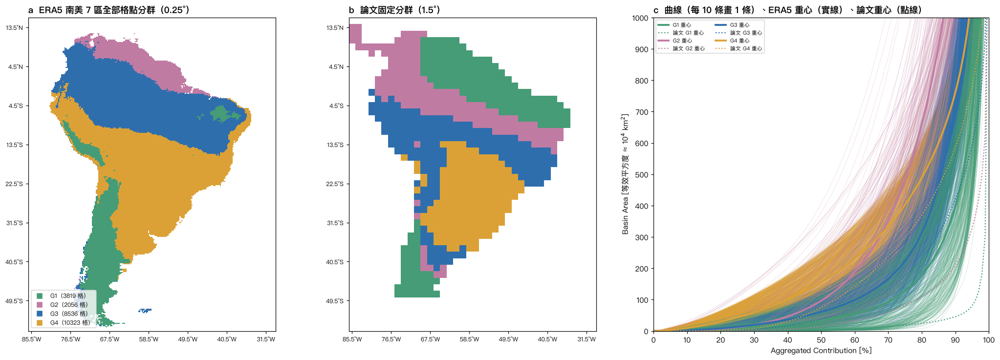

In [13]:
_glat = np.arange(gl_lat.min(), gl_lat.max() + 0.125, 0.25)
_glon = np.arange(gl_lon.min(), gl_lon.max() + 0.125, 0.25)
def e5_grid(labels, mask):
    G = np.full((_glat.size, _glon.size), np.nan)
    G[np.round((gl_lat[mask] - _glat[0]) / 0.25).astype(int), np.round((gl_lon[mask] - _glon[0]) / 0.25).astype(int)] = labels[mask]
    return G

fig, (axa, axp, axb) = plt.subplots(1, 3, figsize=(19, 6.8), gridspec_kw={"width_ratios": [1, 1, 1.2]})
axa.pcolormesh(_glon, _glat, e5_grid(gl_sagroup, gl_sa), cmap=gg_cmap, norm=gg_norm, shading="nearest")
axp.pcolormesh(gg_glon, gg_glat, gg_grid, cmap=gg_cmap, norm=gg_norm, shading="nearest")
e5_mapax(axa, "a  ERA5 南美 7 區全部格點分群（0.25°）"); e5_mapax(axp, "b  論文固定分群（1.5°）")
for g in range(4):
    axa.plot([], [], "s", c=GG_COLORS[g], label=f"G{g+1}（{(sa_group == g).sum()} 格）")
axa.legend(loc="lower left", fontsize=8)
_xc = gl_X[gg_idx100]
for g in [3, 2, 1, 0]:
    m = np.nonzero(sa_group == g)[0][::10]
    axb.add_collection(LineCollection([np.column_stack([_xc, f]) for f in sa_feat[m]], colors=GG_COLORS[g], linewidths=0.4, alpha=0.35))
for g in range(4):
    axb.plot(_xc, sa_feat[sa_group == g].mean(0), c=GG_COLORS[g], lw=2.5, label=f"G{g+1} 重心")
    axb.plot(gg_X[0][gg_idx100], gg_feat[gg_group == g].mean(0), c=GG_COLORS[g], lw=1.5, ls=":", label=f"論文 G{g+1} 重心")
axb.set_xlim(0, 100); axb.set_ylim(0, 1000)
axb.set_xticks(range(0, 101, 10)); axb.set_yticks(range(0, 1001, 100))
axb.set_xlabel("Aggregated Contribution [%]"); axb.set_ylabel("Basin Area [等效平方度 ≈ 10$^4$ km$^2$]")
axb.legend(loc="upper left", fontsize=7, ncol=2)
axb.set_title("c  曲線（每 10 條畫 1 條）、ERA5 重心（實線）、論文重心（點線）", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig2_ERA5_SA7_all.png", dpi=200, bbox_inches="tight"); plt.show()

#### Elbow 方法：第三個選 k 的指標

**定義**：對每個 k 跑 k-means，記下群內平方和（WCSS，sklearn 的 `inertia_`）：

$$\text{WCSS}(k) = \sum_{i=1}^{k}\sum_{x\in C_i}\lVert x-\mu_i\rVert^2$$

k 越大 WCSS 一定越小，所以不是找最低點，而是找曲線**由陡變平的轉角（elbow）**：再多分一群也降不了多少，就停在那裡。

**怎麼找 elbow**：肉眼看容易主觀，這裡另外用 Kneedle 的做法客觀標出來：把 k 和 WCSS 都縮放到 0–1，畫一條連接 k = 2 和 k = 9 兩端的直線，**離這條直線最遠（往下凹最多）的 k** 就是 elbow。

設定和 CH、DB 一樣（ERA5 南美 7 區：`KMeans(k, n_init=10, random_state=0)`；作者資料：`KMeans(k, n_init=20, random_state=0)`），k = 2–9，和 CH 並排比較，圖上標出 k = 4（論文）。

ERA5 南美 7 區（24,734 格，cos 校正）
  k        WCSS     比前一個 k 下降    離連線距離        CH
  2     4.165e+10                       0.000       20,454
  3      3.03e+10          27.3%        0.214       18,692
  4     2.141e+10          29.3%        0.351       21,055
  5      1.67e+10          22.0%        0.356       21,984   ← elbow   ← CH 最高
  6     1.409e+10          15.6%        0.295       21,756
  7     1.231e+10          12.7%        0.209       21,359
  8     1.088e+10          11.6%        0.111       21,167
  9     9.864e+09           9.4%        0.000       20,751
  Elbow k = 5，CH 最佳 k = 5；k = 4 的 WCSS 比 k = 3 少 29.3%

作者資料 GLEAM+GPM pversion（724 格）
  k        WCSS     比前一個 k 下降    離連線距離        CH
  2     2.122e+08                       0.000        2,220
  3     1.104e+08          48.0%        0.413        2,463
  4     6.804e+07          38.4%        0.501        2,810   ← elbow
  5     5.192e+07          23.7%        0.447        2,814   ← CH 最高
  6     4.285e+07          17.5%      

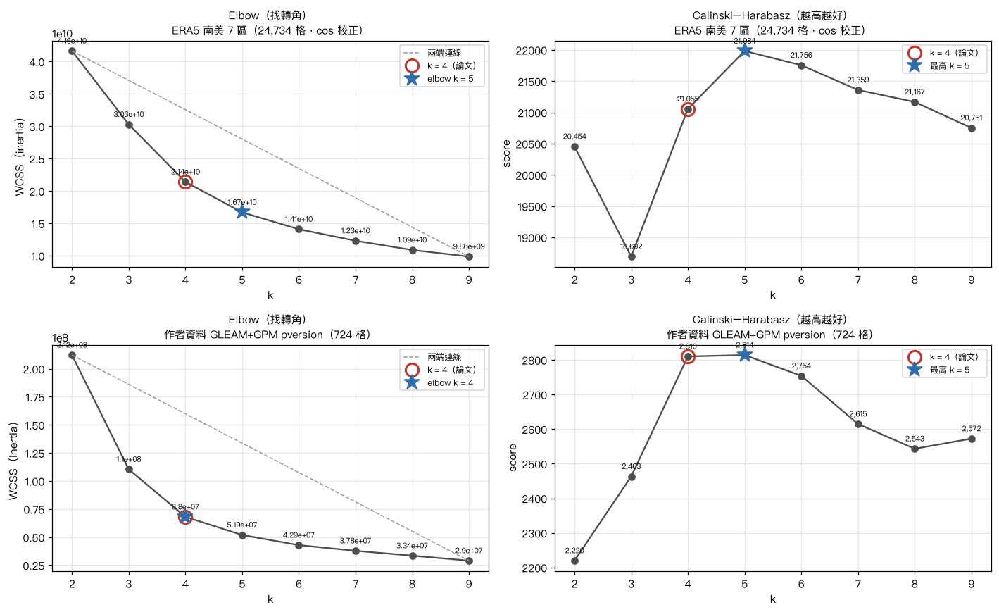

In [ ]:
def elbow_k(ks, w):
    # Kneedle：k、WCSS 縮放到 0–1 後，離兩端連線最遠的點
    x = (ks - ks[0]) / (ks[-1] - ks[0]); y = (w - w.min()) / (w.max() - w.min())
    d = (1 - x) - y                                         # 連線 y = 1 − x 與曲線的垂直距離（往下凹為正）
    return ks[np.argmax(d)], d

_ks = np.arange(2, 10)
wcss_sa = np.array([KMeans(k, n_init=10, random_state=0).fit(sa_feat).inertia_ for k in _ks])
wcss_gg = np.array([KMeans(k, n_init=20, random_state=0).fit(gg_feat).inertia_ for k in _ks])
_rows = [("ERA5 南美 7 區（24,734 格，cos 校正）", np.array(sa_ch)[:8], wcss_sa),
         ("作者資料 GLEAM+GPM pversion（724 格）", np.array(gg_ch)[:8], wcss_gg)]
for name, ch, w in _rows:
    ek, d = elbow_k(_ks, w)
    print(name)
    print("  k        WCSS     比前一個 k 下降    離連線距離        CH")
    for i, k in enumerate(_ks):
        drop = "" if i == 0 else f"{(1 - w[i] / w[i-1]) * 100:6.1f}%"
        print(f"  {k}  {w[i]:12.4g}   {drop:>12}       {d[i]:6.3f}    {ch[i]:9,.0f}" + ("   ← elbow" if k == ek else "") + ("   ← CH 最高" if ch[i] == ch.max() else ""))
    print(f"  Elbow k = {ek}，CH 最佳 k = {_ks[np.argmax(ch)]}；k = 4 的 WCSS 比 k = 3 少 {(1 - w[2] / w[1]) * 100:.1f}%\n")

fig, axs = plt.subplots(2, 2, figsize=(13, 8))
for r, (name, ch, w) in enumerate(_rows):
    ek, d = elbow_k(_ks, w)
    ax = axs[r, 0]
    ax.plot(_ks, w, "o-", c="0.3")
    ax.plot([_ks[0], _ks[-1]], [w[0], w[-1]], ls="--", c="0.6", lw=1, label="兩端連線")
    ax.plot(4, w[2], "o", ms=12, mfc="none", mec="#C0392B", mew=2, label="k = 4（論文）")
    ax.plot(ek, w[list(_ks).index(ek)], "*", ms=15, c="#2E6EAD", label=f"elbow k = {ek}")
    for k, v in zip(_ks, w):
        ax.annotate(f"{v:.3g}", (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
    ax.set_xticks(_ks); ax.set_xlabel("k"); ax.set_ylabel("WCSS（inertia）")
    ax.set_title(f"Elbow（找轉角）\n{name}", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax = axs[r, 1]; bk = _ks[np.argmax(ch)]
    ax.plot(_ks, ch, "o-", c="0.3")
    ax.plot(4, ch[2], "o", ms=12, mfc="none", mec="#C0392B", mew=2, label="k = 4（論文）")
    ax.plot(bk, ch.max(), "*", ms=15, c="#2E6EAD", label=f"最高 k = {bk}")
    for k, v in zip(_ks, ch):
        ax.annotate(f"{v:,.0f}", (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
    ax.set_xticks(_ks); ax.set_xlabel("k"); ax.set_ylabel("score")
    ax.set_title(f"Calinski–Harabasz（越高越好）\n{name}", fontsize=10); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_Elbow_ERA5_SA7.png", dpi=200, bbox_inches="tight"); plt.show()

**結果**：

- **作者資料（724 格）**：elbow 在 **k = 4**（離連線 0.501，k = 5 是 0.447），k = 3 → 4 的 WCSS 還降了 38%，k = 4 → 5 只剩 24%，轉角明顯；CH 最高是 k = 5，但 k = 4 幾乎一樣（2,810 vs 2,814）。兩個指標合起來支持論文選 4 群。
- **ERA5 南美 7 區（24,734 格）**：elbow 落在 **k = 5**，但 k = 4 和 k = 5 離連線的距離幾乎一樣（0.351 vs 0.356），轉角比作者資料平緩，k = 3 → 4 → 5 的下降是 29% → 22%，沒有一個明顯的「凹點」；CH 也是 k = 5 最高、k = 4 低 4%。
- 和 CH、DB 比：elbow 和 CH 在兩份資料都指向 4–5 群，DB 則一律偏好 k = 2。ERA5 的轉角比作者資料不明顯，表示 ERA5 的曲線比較是連續變化、群和群之間沒有那麼分開。

**Elbow 的 k = 4 vs CH 的 k = 4：分出來的群一樣嗎？**

Elbow（WCSS）和 CH 都只是**拿 k-means 的結果打分數**，不會自己分群；兩者在 k = 4 用的是同一個 k-means（`KMeans(4, n_init=10, random_state=0)`）。7.3 節最後畫圖用的是 `n_init=50` 重跑的結果。下面把三者並排：

- 上排：elbow / CH 打分數用的 k = 4（`n_init=10`）、7.3 節畫圖用的 k = 4（`n_init=50`）、兩者不同的格點（紅色）。
- 下排：兩者的各群重心曲線疊在一起（實線 = `n_init=10`，點線 = `n_init=50`），以及 k = 5（elbow 與 CH 在 ERA5 上選的 k）的地圖和重心，對照「真正會改變結果的是 k」。

群一律依 C = 50% 的面積 A50 中位數由小到大命名。

k = 4：elbow/CH 打分數用（n_init=10） vs 7.3 畫圖用（n_init=50） → 同名一致 99.97%，不同 7 / 24,734 格
各群格數  n_init=10: 3817 / 2056 / 8531 / 10330   n_init=50: 3819 / 2056 / 8536 / 10323
各群重心曲線最大差（作者式 deg²）：G1 0.12 / G2 0.00 / G3 0.26 / G4 0.15
k = 5 各群格數：G1 3677 / G2 2477 / G3 8432 / G4 994 / G5 9154


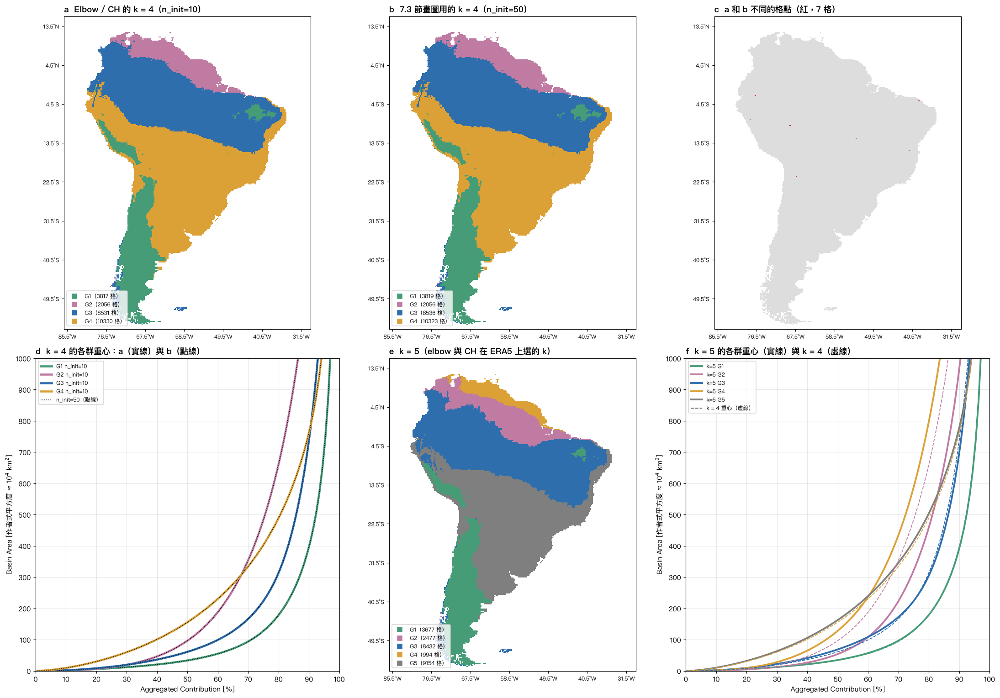

In [ ]:
from matplotlib.colors import ListedColormap as _LC, BoundaryNorm as _BN
def _named(lab, k):
    med = [np.median(sa_a50[lab == g]) for g in range(k)]
    rank = np.empty(k, int); rank[np.argsort(med)] = np.arange(k)
    return rank[lab]
def _grid(lab):
    G = np.full((_glat.size, _glon.size), np.nan)
    G[np.round((gl_lat[sa_i] - _glat[0]) / 0.25).astype(int), np.round((gl_lon[sa_i] - _glon[0]) / 0.25).astype(int)] = lab
    return G

cmp_e4 = _named(KMeans(4, n_init=10, random_state=0).fit_predict(sa_feat), 4)   # elbow / CH 打分數用的 k = 4
cmp_c4 = sa_group                                                              # 7.3 節畫圖用的 k = 4（n_init=50）
cmp_k5 = _named(KMeans(5, n_init=50, random_state=0).fit_predict(sa_feat), 5)
_diff = cmp_e4 != cmp_c4
print(f"k = 4：elbow/CH 打分數用（n_init=10） vs 7.3 畫圖用（n_init=50） → 同名一致 {np.mean(~_diff)*100:.2f}%，不同 {_diff.sum()} / {len(sa_i):,} 格")
print("各群格數  n_init=10: " + " / ".join(str((cmp_e4 == g).sum()) for g in range(4)) +
      "   n_init=50: " + " / ".join(str((cmp_c4 == g).sum()) for g in range(4)))
print("各群重心曲線最大差（作者式 deg²）：" + " / ".join(f"G{g+1} {np.abs(sa_feat[cmp_e4 == g].mean(0) - sa_feat[cmp_c4 == g].mean(0)).max():.2f}" for g in range(4)))
print("k = 5 各群格數：" + " / ".join(f"G{g+1} {(cmp_k5 == g).sum()}" for g in range(5)))

_C5 = list(GG_COLORS[:4]) + ["#7F7F7F"]
_cm5, _nm5 = _LC(_C5), _BN(np.arange(-0.5, 5.5), 5)
_xc = gl_X[gg_idx100]
fig, axs = plt.subplots(2, 3, figsize=(20, 14))
axs[0, 0].pcolormesh(_glon, _glat, _grid(cmp_e4), cmap=gg_cmap, norm=gg_norm, shading="nearest")
e5_mapax(axs[0, 0], "a  Elbow / CH 的 k = 4（n_init=10）")
axs[0, 1].pcolormesh(_glon, _glat, _grid(cmp_c4), cmap=gg_cmap, norm=gg_norm, shading="nearest")
e5_mapax(axs[0, 1], "b  7.3 節畫圖用的 k = 4（n_init=50）")
for ax, lab in [(axs[0, 0], cmp_e4), (axs[0, 1], cmp_c4)]:
    for g in range(4):
        ax.plot([], [], "s", c=GG_COLORS[g], label=f"G{g+1}（{(lab == g).sum()} 格）")
    ax.legend(loc="lower left", fontsize=8)
axs[0, 2].pcolormesh(_glon, _glat, _grid(_diff.astype(float)), cmap=_LC(["#DDDDDD", "#C0392B"]), vmin=0, vmax=1, shading="nearest")
e5_mapax(axs[0, 2], f"c  a 和 b 不同的格點（紅，{_diff.sum()} 格）")

ax = axs[1, 0]
for g in range(4):
    ax.plot(_xc, sa_feat[cmp_e4 == g].mean(0), c=GG_COLORS[g], lw=3, label=f"G{g+1} n_init=10")
    ax.plot(_xc, sa_feat[cmp_c4 == g].mean(0), c="k", lw=1, ls=":")
ax.plot([], [], c="k", lw=1, ls=":", label="n_init=50（點線）")
ax.set_xlim(0, 100); ax.set_ylim(0, 1000); ax.set_xticks(range(0, 101, 10)); ax.set_yticks(range(0, 1001, 100))
ax.set_xlabel("Aggregated Contribution [%]"); ax.set_ylabel("Basin Area [作者式平方度 ≈ 10$^4$ km$^2$]")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
ax.set_title("d  k = 4 的各群重心：a（實線）與 b（點線）", loc="left", fontweight="bold")

axs[1, 1].pcolormesh(_glon, _glat, _grid(cmp_k5), cmap=_cm5, norm=_nm5, shading="nearest")
e5_mapax(axs[1, 1], "e  k = 5（elbow 與 CH 在 ERA5 上選的 k）")
for g in range(5):
    axs[1, 1].plot([], [], "s", c=_C5[g], label=f"G{g+1}（{(cmp_k5 == g).sum()} 格）")
axs[1, 1].legend(loc="lower left", fontsize=8)
ax = axs[1, 2]
for g in range(5):
    ax.plot(_xc, sa_feat[cmp_k5 == g].mean(0), c=_C5[g], lw=2.5, label=f"k=5 G{g+1}")
for g in range(4):
    ax.plot(_xc, sa_feat[cmp_c4 == g].mean(0), c=GG_COLORS[g], lw=1.2, ls="--")
ax.plot([], [], c="0.3", lw=1.2, ls="--", label="k = 4 重心（虛線）")
ax.set_xlim(0, 100); ax.set_ylim(0, 1000); ax.set_xticks(range(0, 101, 10)); ax.set_yticks(range(0, 1001, 100))
ax.set_xlabel("Aggregated Contribution [%]"); ax.set_ylabel("Basin Area [作者式平方度 ≈ 10$^4$ km$^2$]")
ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
ax.set_title("f  k = 5 的各群重心（實線）與 k = 4（虛線）", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_Elbow_vs_CH_k4_SA7.png", dpi=200, bbox_inches="tight"); plt.show()

**結果**：Elbow 和 CH 的 k = 4 是**同一個分群**：只有 7 / 24,734 格（0.03%）不同（`n_init=10` vs `n_init=50` 的隨機初始化差異），各群重心曲線最大只差 0.26 作者式平方度，地圖和曲線肉眼看不出差別。指標只決定 k，k 一樣，面積就一樣。

真正會改變結果的是 k：k = 5 時，北岸的 G2 被切出一小群（994 格），面積最大的那一群（原本 k = 4 的 G4，拉普拉塔流域）大致保留下來（9,154 格），其他群幾乎不動。

### 其他各洲：用各洲自己的格點分群

和 7.3 南美洲完全一樣的做法，換成其他各洲。**每一洲只用自己的 0.25° 格點分群**（全部格點、不截斷、作者算法、100 點線性面積），四個重心只由該洲的曲線決定：

- CH 測 k = 2–9（`KMeans(n_init=10, random_state=0)`，全部格點，不抽樣），圖上標出最高的 k 和 k = 4；
- k-means 4 群（`n_init=50, random_state=0`），依 C = 50% 的面積中位數由小到大命名 G1–G4；
- 地圖、曲線和各群重心，以及各群格點數、A50 中位數、轉折點中位數（Q1–Q3）。

各洲用 IPCC AR6 區域定義：

| 洲 | AR6 區域 |
|---|---|
| 北美洲（含中美、加勒比） | NWN, NEN, WNA, CNA, ENA, NCA, SCA, CAR |
| 歐洲 | NEU, WCE, EEU, MED（MED 包含北非沿岸和中東沿海，照 AR6 的分組歸在歐洲） |
| 非洲 | SAH, WAF, CAF, NEAF, SEAF, WSAF, ESAF, MDG |
| 亞洲 | WSB, ESB, RFE, WCA, ECA, TIB, EAS, ARP, SAS, SEA |
| 大洋洲 | NAU, CAU, EAU, SAU, NZ |

注意：曲線的來源範圍和 7.3 一樣是 ERA5 nc 的設定（各 AR6 區域的追蹤範圍），不是只算該洲境內的來源。

#### ⚠ 延伸到其他洲時一定要處理：面積隨 cos(緯度) 變化

經緯度網格的格子面積和 cos(緯度) 成正比（見 `Mongolia/DENSITY.md`）：0.25° 格子在赤道約 773 km²，30° 約 670 km²，50° 約 497 km²，60° 只剩約 386 km²（赤道的一半）。

**作者沒有做這個校正**：作者資料的面積是「格數 × 2.25 平方度」，每一格不論緯度都算一樣大，論文再把 1 平方度當成 10⁴ km²（例如 Sorriso 的關鍵上風盆地 337,500 km² = 15 格 × 22,500 km²）。

**在南美洲為什麼影響不大**：作者的 724 格雖然從 13.5°N 延伸到 48°S，但大部分在低緯度——|緯度| 的中位數只有 12°，75% 的格子在 24° 以內，超過 30° 的只有 16%、超過 40° 的只有 6%。cos(緯度) 的中位數是 0.98、平均 0.94，把格數當面積平均只高估約 7%；G1–G4 各群的 cos 中位數是 0.99 / 0.99 / 0.97 / 0.90。只有巴塔哥尼亞、智利南部等少數格子（cos ≈ 0.67–0.77）會被高估 30–50%。整體來看，724 格中有 74% 在回歸線以內（|緯度| ≤ 23.5°），cos(緯度) < 0.8 的只有 8.7%。所以作者在南美洲忽略 cos 緯度，對整體分群和轉折點的影響有限（但嚴格來說，高緯度那一小部分的面積是被高估的）。

**延伸到其他洲時就不能忽略**：北美洲、歐洲的 |緯度| 中位數約 45–48°（cos ≈ 0.66–0.70），亞洲約 38°，大部分格子都在中高緯度，「格數」和「真實面積」差 1.4–2 倍，而且差異隨緯度系統性變化。因為轉折點的角度 θ 依賴面積軸的尺度（作者把 y ÷ 10），單位一偏，θ、θ′ 和找到的峰都跟著偏；分群用的線性面積特徵也會被拉開或壓縮。7.9 的前後比較顯示：低緯度的南美洲、非洲校正前後幾乎不變，但北美洲的 CH 最高從 k = 7 變 k = 5、亞洲從 k = 4 變 k = 7、歐洲的轉折點整體往前移。

這裡的做法：把 ERA5 的真實面積除以「目標格點緯度上 1 平方度的面積」（≈ 12,364 × cos 緯度 km²），換成作者式的「格數平方度」，讓各洲和論文用同一種單位。這仍是近似（曲線的來源格點分布在各個緯度，這裡用目標格點的緯度代表），高緯度各洲的結果要保守解讀。

**物理上，真實面積才是對的**：作者的格數慣例只是為了和論文對齊。如果要做嚴謹的全球版，應該用真實面積（乘 cos 緯度），並在排序來源時用「單位面積的貢獻」（ERA5 nc 建曲線時已經是這樣做的），而不是格數。

In [14]:
e5_cont = {}                 # 各洲結果，給最後的總表用
_KS = np.arange(2, 10)

def e5_continent(name, regions, tag):
    m = np.isin(gl_rg, regions)
    idx = np.nonzero(m)[0]
    feat, a50, tp = gl_feat[idx], gl_a50[idx], gl_tp[idx]
    lat, lon = gl_lat[idx], gl_lon[idx]
    t0 = time.time()
    ch = np.array([calinski_harabasz_score(feat, KMeans(k, n_init=10, random_state=0).fit_predict(feat)) for k in _KS])
    lab = KMeans(n_clusters=4, n_init=50, random_state=0).fit_predict(feat)
    med = [np.median(a50[lab == g]) for g in range(4)]
    rank = np.empty(4, int); rank[np.argsort(med)] = np.arange(4)
    grp = rank[lab]
    best = _KS[np.argmax(ch)]
    print(f"{name}：{len(idx)} 格（{', '.join(regions)}），計算 {time.time() - t0:.0f} 秒")
    print("CH：" + "  ".join(f"k={k}:{v:,.0f}" for k, v in zip(_KS, ch)) + f"\nCH 最高 k = {best}；k = 4 是最高分的 {ch[2] / ch.max() * 100:.1f}%")
    print("\n        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）")
    tpm = []
    for g in range(4):
        mm = grp == g; t = tp[mm]; tpm.append(np.nanmedian(t))
        print(f"G{g+1}   {mm.sum():6d} ({mm.mean()*100:4.1f}%)      {np.median(a50[mm]):6.0f}                  "
              f"{np.nanmedian(t):5.1f} ({np.nanpercentile(t, 25):.1f}–{np.nanpercentile(t, 75):.1f})")
    e5_cont[name] = dict(n=len(idx), best=best, ratio=ch[2] / ch.max(), tp=tpm, share=[(grp == g).mean() for g in range(4)])

    # CH 圖
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(_KS, ch, "o-", c="0.3")
    ax.plot(4, ch[2], "o", ms=12, mfc="none", mec="#C0392B", mew=2, label="k = 4（論文）")
    ax.plot(best, ch.max(), "*", ms=15, c="#2E6EAD", label=f"最高 k = {best}")
    for k, v in zip(_KS, ch):
        ax.annotate(f"{v:,.0f}", (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_xticks(_KS); ax.set_xlabel("k"); ax.set_ylabel("score")
    ax.set_title(f"Calinski–Harabasz（越高越好）\nERA5 {name}（{len(idx):,} 格）"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(FIG_DIR / f"Fig_CH_ERA5_{tag}.png", dpi=200, bbox_inches="tight"); plt.show()

    # 地圖＋曲線
    glat = np.arange(lat.min(), lat.max() + 0.125, 0.25); glon = np.arange(lon.min(), lon.max() + 0.125, 0.25)
    G = np.full((glat.size, glon.size), np.nan)
    G[np.round((lat - glat[0]) / 0.25).astype(int), np.round((lon - glon[0]) / 0.25).astype(int)] = grp
    w = (lon.max() - lon.min()) / (lat.max() - lat.min())
    fig, (axa, axb) = plt.subplots(1, 2, figsize=(7 * min(max(w, 0.8), 2.2) + 7, 6.5),
                                   gridspec_kw={"width_ratios": [min(max(w, 0.8), 2.2), 1]})
    axa.pcolormesh(glon, glat, G, cmap=gg_cmap, norm=gg_norm, shading="nearest")
    axa.set_aspect("equal"); axa.set_xlabel("經度"); axa.set_ylabel("緯度")
    for g in range(4):
        axa.plot([], [], "s", c=GG_COLORS[g], label=f"G{g+1}（{(grp == g).sum()} 格）")
    axa.legend(loc="best", fontsize=8)
    axa.set_title(f"a  ERA5 {name} k = 4（0.25°）", loc="left", fontweight="bold")
    xc = gl_X[gg_idx100]
    for g in [3, 2, 1, 0]:
        sel = np.nonzero(grp == g)[0][::10]
        axb.add_collection(LineCollection([np.column_stack([xc, f]) for f in feat[sel]], colors=GG_COLORS[g], linewidths=0.4, alpha=0.3))
    for g in range(4):
        axb.plot(xc, feat[grp == g].mean(0), c=GG_COLORS[g], lw=2.5, label=f"G{g+1} 重心")
    axb.set_xlim(0, 100); axb.set_ylim(0, 1000)
    axb.set_xticks(range(0, 101, 10)); axb.set_yticks(range(0, 1001, 100))
    axb.set_xlabel("Aggregated Contribution [%]"); axb.set_ylabel("Basin Area [等效平方度 ≈ 10$^4$ km$^2$]")
    axb.legend(loc="upper left", fontsize=8)
    axb.set_title("b  曲線（每 10 條畫 1 條）與各群重心", loc="left", fontweight="bold")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"Fig2_ERA5_{tag}.png", dpi=200, bbox_inches="tight"); plt.show()
    return grp

# 南美（7.3）也放進總表
e5_cont["南美洲"] = dict(n=len(sa_i), best=_KS[np.argmax(np.array(sa_ch)[:8])], ratio=sa_ch[2] / max(sa_ch[:8]),
                        tp=[np.nanmedian(gl_tp[sa_i][sa_group == g]) for g in range(4)],
                        share=[(sa_group == g).mean() for g in range(4)])

### 7.4 北美洲（含中美洲、加勒比海）

北美洲：30506 格（NWN, NEN, WNA, CNA, ENA, NCA, SCA, CAR），計算 4 秒
CH：k=2:33,025  k=3:36,082  k=4:36,167  k=5:37,769  k=6:37,558  k=7:36,544  k=8:36,105  k=9:35,805
CH 最高 k = 5；k = 4 是最高分的 95.8%

        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）
G1    15565 (51.0%)         136                   74.1 (54.3–85.4)
G2     6494 (21.3%)         188                   61.1 (43.1–66.0)
G3     7079 (23.2%)         504                   89.1 (26.2–92.7)
G4     1368 ( 4.5%)         855                   14.8 (8.0–28.0)


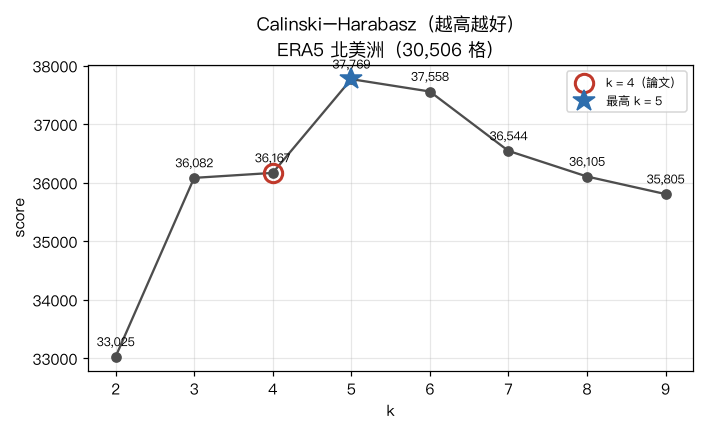

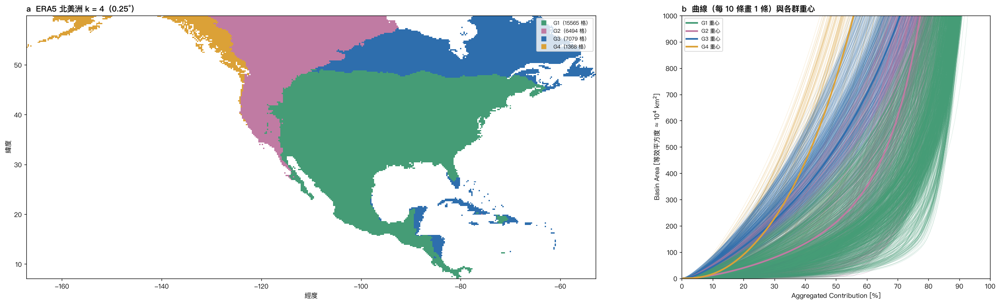

In [15]:
_ = e5_continent("北美洲", ["NWN", "NEN", "WNA", "CNA", "ENA", "NCA", "SCA", "CAR"], "NAm")

### 7.5 歐洲（MED 地中海區包含北非沿岸和中東沿海，照 AR6 的分組歸在歐洲）

歐洲：19865 格（NEU, WCE, EEU, MED），計算 3 秒
CH：k=2:24,484  k=3:23,537  k=4:23,236  k=5:21,629  k=6:20,411  k=7:20,138  k=8:19,846  k=9:19,793
CH 最高 k = 2；k = 4 是最高分的 94.9%

        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）
G1     3452 (17.4%)         228                   23.0 (8.8–45.3)
G2     7460 (37.6%)         255                   17.0 (5.1–50.0)
G3     6222 (31.3%)         491                    5.0 (3.8–18.9)
G4     2731 (13.7%)         575                    4.8 (3.6–8.6)


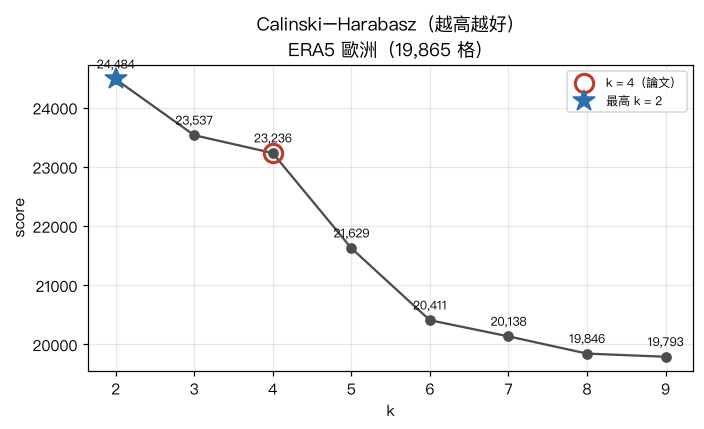

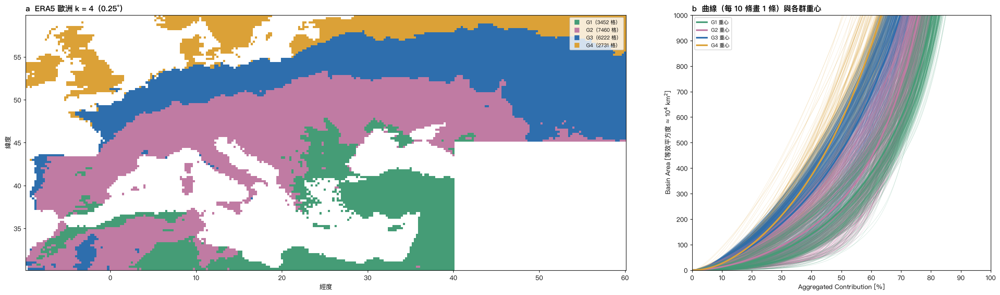

In [16]:
_ = e5_continent("歐洲", ["NEU", "WCE", "EEU", "MED"], "Eur")

### 7.6 非洲

非洲：38432 格（SAH, WAF, CAF, NEAF, SEAF, WSAF, ESAF, MDG），計算 5 秒
CH：k=2:158,151  k=3:160,256  k=4:196,338  k=5:194,017  k=6:185,562  k=7:183,547  k=8:179,277  k=9:176,974
CH 最高 k = 4；k = 4 是最高分的 100.0%

        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）
G1    15550 (40.5%)          98                   91.4 (80.6–95.1)
G2     5931 (15.4%)         139                   61.8 (43.9–72.9)
G3     9626 (25.0%)         290                   49.9 (8.9–60.7)
G4     7325 (19.1%)         453                   38.7 (22.5–58.5)


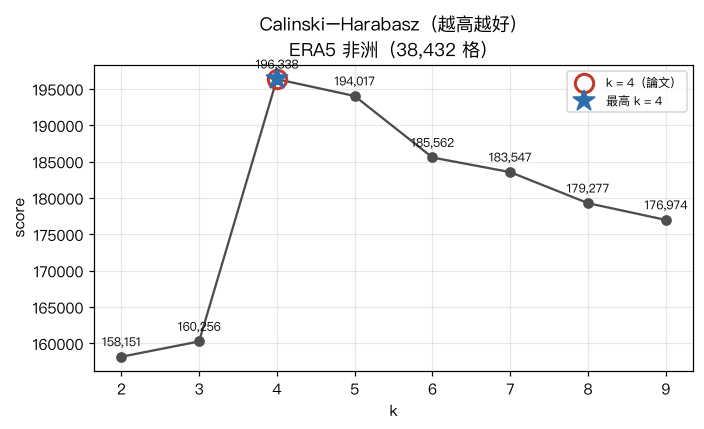

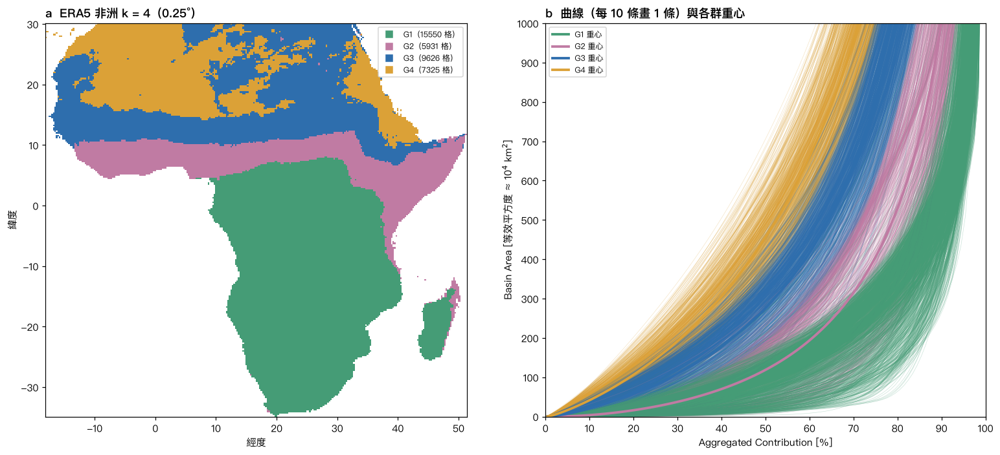

In [17]:
_ = e5_continent("非洲", ["SAH", "WAF", "CAF", "NEAF", "SEAF", "WSAF", "ESAF", "MDG"], "Afr")

### 7.7 亞洲

亞洲：60348 格（WSB, ESB, RFE, WCA, ECA, TIB, EAS, ARP, SAS, SEA），計算 9 秒
CH：k=2:101,226  k=3:125,573  k=4:123,846  k=5:151,491  k=6:162,481  k=7:173,924  k=8:170,253  k=9:165,973
CH 最高 k = 7；k = 4 是最高分的 71.2%

        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）
G1     3669 ( 6.1%)          18                   82.9 (70.1–89.6)
G2    10968 (18.2%)         113                   68.2 (52.3–74.1)
G3    24268 (40.2%)         260                   37.1 (15.0–50.6)
G4    21443 (35.5%)         681                    6.4 (3.2–25.6)


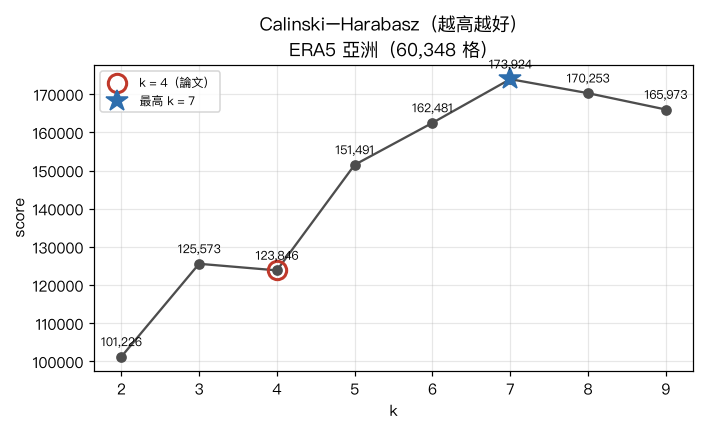

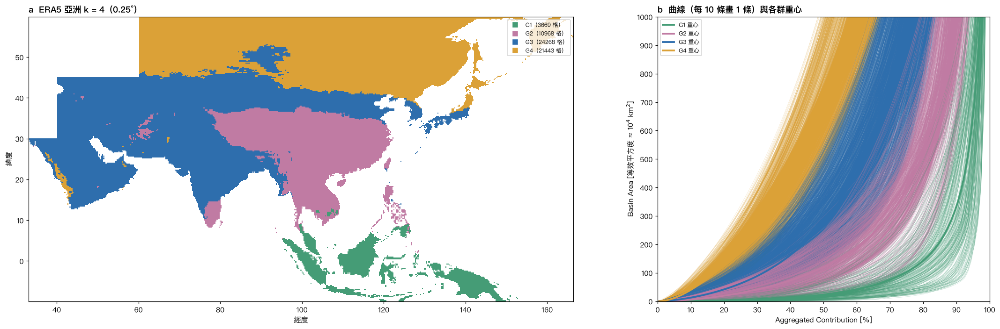

In [18]:
_ = e5_continent("亞洲", ["WSB", "ESB", "RFE", "WCA", "ECA", "TIB", "EAS", "ARP", "SAS", "SEA"], "Asia")

### 7.8 大洋洲

大洋洲：11661 格（NAU, CAU, EAU, SAU, NZ），計算 2 秒
CH：k=2:7,543  k=3:9,733  k=4:8,484  k=5:8,364  k=6:8,442  k=7:8,200  k=8:8,101  k=9:8,001
CH 最高 k = 3；k = 4 是最高分的 87.2%

        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）
G1      762 ( 6.5%)          72                   44.6 (19.7–83.2)
G2     1878 (16.1%)          80                   77.4 (40.8–95.4)
G3     5834 (50.0%)          99                   87.3 (77.1–97.5)
G4     3187 (27.3%)         166                   97.1 (30.7–97.8)


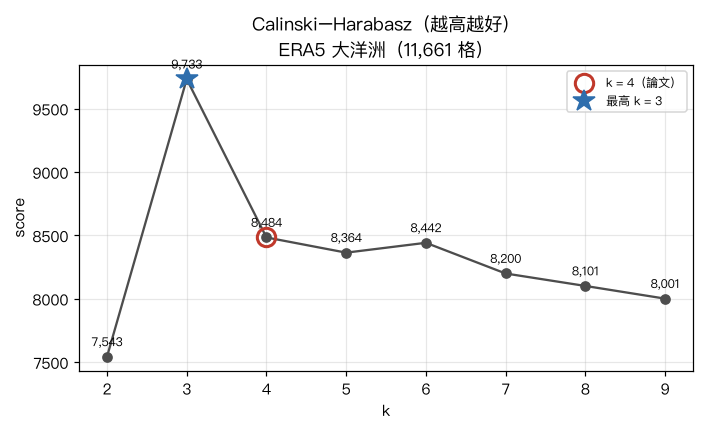

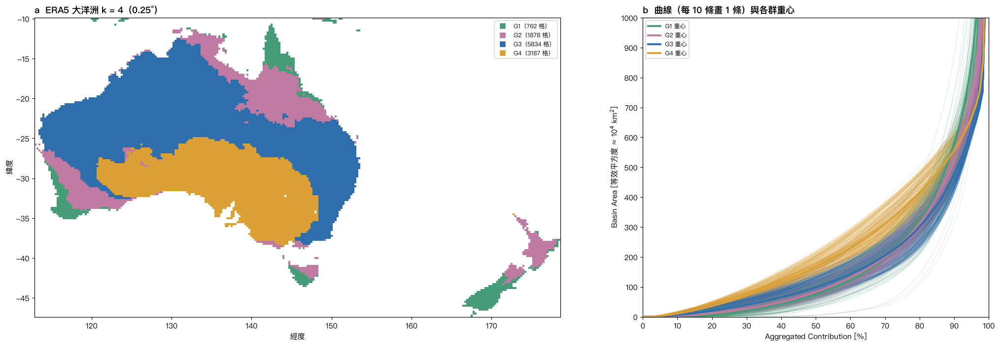

In [19]:
_ = e5_continent("大洋洲", ["NAU", "CAU", "EAU", "SAU", "NZ"], "Oce")

### 各洲總表

In [20]:
_order = ["南美洲", "北美洲", "歐洲", "非洲", "亞洲", "大洋洲"]
print(f"{'洲':<6}{'格數':>8}{'CH 最高 k':>10}{'CH(k=4)/CH(max)':>17}   轉折點中位數 G1 / G2 / G3 / G4        G1→G4 遞減？   各群比例")
for n in _order:
    r = e5_cont[n]; t = r["tp"]
    dec = all(t[g] > t[g + 1] for g in range(3))
    print(f"{n:<6}{r['n']:>8,}{r['best']:>10}{r['ratio']*100:>16.1f}%   " + " / ".join(f"{v:5.1f}" for v in t) +
          f"     {'是' if dec else '否':>4}       " + " / ".join(f"{s*100:.0f}%" for s in r["share"]))
print("\n（論文 GLEAM 724 格：轉折點 95.3 / 68.6 / 48.0 / 35.5，G1→G4 遞減；CH 最高 k = 5，k = 4 是 99.9%）")

# ---- cos 緯度校正前後比較 ----
def e5_stats(feat, a50, tp, mask):
    f, a, t = feat[mask], a50[mask], tp[mask]
    ch = np.array([calinski_harabasz_score(f, KMeans(k, n_init=10, random_state=0).fit_predict(f)) for k in _KS])
    lab = KMeans(n_clusters=4, n_init=50, random_state=0).fit_predict(f)
    med = [np.median(a[lab == g]) for g in range(4)]
    rank = np.empty(4, int); rank[np.argsort(med)] = np.arange(4); grp = rank[lab]
    tpm = [np.nanmedian(t[grp == g]) for g in range(4)]
    return dict(best=_KS[np.argmax(ch)], ratio=ch[2] / ch.max(), tp=tpm, share=[(grp == g).mean() for g in range(4)], grp=grp)

_regions = {"南美洲": E5_SA, "北美洲": ["NWN", "NEN", "WNA", "CNA", "ENA", "NCA", "SCA", "CAR"], "歐洲": ["NEU", "WCE", "EEU", "MED"],
            "非洲": ["SAH", "WAF", "CAF", "NEAF", "SEAF", "WSAF", "ESAF", "MDG"],
            "亞洲": ["WSB", "ESB", "RFE", "WCA", "ECA", "TIB", "EAS", "ARP", "SAS", "SEA"], "大洋洲": ["NAU", "CAU", "EAU", "SAU", "NZ"]}
print("\n=== cos 緯度校正前後比較（每洲只用自己的格點）===")
print(f"{'洲':<6}{'版本':<8}{'CH 最高 k':>9}{'k=4/max':>9}   轉折點中位數 G1 / G2 / G3 / G4     遞減   各群比例")
for n in _order:
    mask = np.isin(gl_rg, _regions[n])
    lat_med = np.median(np.abs(gl_lat[mask]))
    for ver, r in [("未校正", e5_stats(gl_feat_nc, gl_a50_nc, gl_tp_nc, mask)), ("cos 校正", e5_stats(gl_feat, gl_a50, gl_tp, mask))]:
        dec = all(r["tp"][g] > r["tp"][g + 1] for g in range(3))
        print(f"{n:<6}{ver:<8}{r['best']:>9}{r['ratio']*100:>8.1f}%   " + " / ".join(f"{v:5.1f}" for v in r["tp"]) +
              f"   {'是' if dec else '否':>3}   " + " / ".join(f"{s*100:.0f}%" for s in r["share"]))
        if n == "南美洲":
            g = np.full(gl_n, -1); g[mask] = r["grp"]
            m = mask & (gl_paper >= 0)
            v = e5_vote(g, mask); vv = v >= 0
            print(f"{'':<14}和論文：0.25° 最佳對應 {gg_agree(g[m], gl_paper[m])*100:.1f}%，多數決 1.5° 最佳對應 {gg_agree(v[vv], gg_group[vv])*100:.1f}%")
    print(f"{'':<14}（|緯度| 中位數 {lat_med:.0f}°，cos = {np.cos(np.deg2rad(lat_med)):.2f}）")

洲           格數   CH 最高 k  CH(k=4)/CH(max)   轉折點中位數 G1 / G2 / G3 / G4        G1→G4 遞減？   各群比例
南美洲     24,734         5            95.8%    79.2 /  48.4 /  78.7 /  89.9        否       15% / 8% / 35% / 42%
北美洲     30,506         5            95.8%    74.1 /  61.1 /  89.1 /  14.8        否       51% / 21% / 23% / 4%
歐洲      19,865         2            94.9%    23.0 /  17.0 /   5.0 /   4.8        是       17% / 38% / 31% / 14%
非洲      38,432         4           100.0%    91.4 /  61.8 /  49.9 /  38.7        是       40% / 15% / 25% / 19%
亞洲      60,348         7            71.2%    82.9 /  68.2 /  37.1 /   6.4        是       6% / 18% / 40% / 36%
大洋洲     11,661         3            87.2%    44.6 /  77.4 /  87.3 /  97.1        否       7% / 16% / 50% / 27%

（論文 GLEAM 724 格：轉折點 95.3 / 68.6 / 48.0 / 35.5，G1→G4 遞減；CH 最高 k = 5，k = 4 是 99.9%）

=== cos 緯度校正前後比較（每洲只用自己的格點）===
洲     版本        CH 最高 k  k=4/max   轉折點中位數 G1 / G2 / G3 / G4     遞減   各群比例


南美洲   未校正             5    96.5%    82.2 /  49.1 /  78.6 /  91.0     否   14% / 9% / 36% / 41%
              和論文：0.25° 最佳對應 53.6%，多數決 1.5° 最佳對應 52.9%
南美洲   cos 校正          5    95.8%    79.2 /  48.4 /  78.7 /  89.9     否   15% / 8% / 35% / 42%
              和論文：0.25° 最佳對應 54.8%，多數決 1.5° 最佳對應 55.0%
              （|緯度| 中位數 13°，cos = 0.98）


北美洲   未校正             7    94.0%    66.3 /  79.1 /  27.3 /  89.5     否   26% / 33% / 8% / 32%
北美洲   cos 校正          5    95.8%    74.1 /  61.1 /  89.1 /  14.8     否   51% / 21% / 23% / 4%
              （|緯度| 中位數 45°，cos = 0.70）


歐洲    未校正             2    92.6%    45.7 /  52.7 /  10.8 /  16.9     否   24% / 33% / 33% / 11%
歐洲    cos 校正          2    94.9%    23.0 /  17.0 /   5.0 /   4.8     是   17% / 38% / 31% / 14%
              （|緯度| 中位數 48°，cos = 0.66）


非洲    未校正             4   100.0%    92.3 /  63.2 /  53.4 /  42.1     是   40% / 15% / 25% / 21%
非洲    cos 校正          4   100.0%    91.4 /  61.8 /  49.9 /  38.7     是   40% / 15% / 25% / 19%
              （|緯度| 中位數 15°，cos = 0.97）


亞洲    未校正             4   100.0%    83.1 /  70.8 /  42.6 /  18.3     是   6% / 18% / 49% / 27%
亞洲    cos 校正          7    71.2%    82.9 /  68.2 /  37.1 /   6.4     是   6% / 18% / 40% / 36%
              （|緯度| 中位數 38°，cos = 0.79）


大洋洲   未校正             3    96.6%    79.4 /  82.8 /  97.6 /  97.2     否   10% / 44% / 23% / 23%
大洋洲   cos 校正          3    87.2%    44.6 /  77.4 /  87.3 /  97.1     否   7% / 16% / 50% / 27%
              （|緯度| 中位數 26°，cos = 0.90）


### 7.9 小結

**曲線本身（7.2，不靠分群）**：每個論文 1.5° 格子取全部 0.25° 格點的中位數比較，A50 的 Spearman ρ = 0.66，格點的相對排序大致一致；但 ERA5 的 A50 是作者資料的 3.6 倍，而且各群放大倍數不同（G1 10.5 倍、G2 4.8 倍、G3 2.7 倍、G4 2.2 倍），G4 ÷ G1 的對比從 23.7 倍壓縮成 5.0 倍。

**南美 7 區全部格點分群（7.3）**：CH 在 k = 5 最高、k = 4 次之。四群 14 / 9 / 36 / 41%。和論文的最佳標籤對應：0.25° 逐格 53.6%、多數決合併到 1.5° 後 52.9%。地圖上，G1（智利、巴塔哥尼亞）對應論文 G1 南段；G2（委內瑞拉、蓋亞那）是論文 G1 北段；G3（哥倫比亞—亞馬遜中北部—巴西東北的寬帶）大致對應論文 G2；G4 把論文的 G3 和 G4 合成一大群。依論文分群看轉折點，ERA5 是 65.7 / 80.0 / 87.1 / 93.2%，順序和論文（95 / 69 / 48 / 36）相反。

**結論**：和論文對不上的根本原因是曲線定義不同——論文鎖在南美框內、分母只算框內 724 格陸地來源（Weng et al. 2018 也寫明忽略洲際水氣輸送），ERA5 nc 的來源範圍大很多。只靠這份 nc（只有建好的曲線）無法修正；要可比，需要每個目標格點的 e_track 來源圖，或用 WAM2layers 把追蹤範圍鎖在南美框重跑。

**其他各洲（7.4–7.8，各洲只用自己的格點分群；面積已做 cos 緯度校正）**

| 洲 | 格數 | CH 最高 k | CH(k=4)/CH(max) | 轉折點中位數 G1 / G2 / G3 / G4 | G1→G4 遞減 |
|---|---|---|---|---|---|
| 南美洲 | 24,734 | 5 | 95.8% | 79.2 / 48.4 / 78.7 / 89.9 | 否 |
| 北美洲 | 30,506 | 5 | 95.8% | 74.1 / 61.1 / 89.1 / 14.8 | 否 |
| 歐洲 | 19,865 | 2 | 94.9% | 23.0 / 17.0 / 5.0 / 4.8 | 是 |
| 非洲 | 38,432 | **4** | 100% | 91.4 / 61.8 / 49.9 / 38.7 | **是** |
| 亞洲 | 60,348 | 7 | 71.2% | 82.9 / 68.2 / 37.1 / 6.4 | 是 |
| 大洋洲 | 11,661 | 3 | 87.2% | 44.6 / 77.4 / 87.3 / 97.1 | 否 |

- **cos 緯度校正的影響**（為什麼要校正，見「其他各洲」開頭的 ⚠ 說明）：低緯度的南美洲（|緯度| 中位數 13°）和非洲（15°）幾乎不變；南美和論文的一致比例從 53.6% / 52.9% 小幅升到 54.8% / 55.0%。高緯度的北美洲（45°）、歐洲（48°）、亞洲（38°）變化很大：北美的 CH 最高從 k = 7 變 k = 5，亞洲從 k = 4 變 k = 7，歐洲的轉折點整體往前移。這表示高緯度的結果對面積單位很敏感，而校正本身又是用目標格點緯度做的近似，解讀時要保守。
- 校正後，只有**非洲**同時滿足「CH 在 k = 4 最高」和「轉折點從 G1 到 G4 遞減」，結構最像論文（赤道以南 G1、赤道北側到東非高原 G2、薩赫爾 G3、撒哈拉 G4）。
- **注意區域邊界的痕跡**：歐洲和亞洲的地圖上有沿著經緯線的直線邊界（例如 40°E、45°N、60°E），剛好是 AR6 區域（run group）的邊界。因為 nc 是每個區域各自跑一組 WAM2layers、追蹤範圍不同，曲線在區域交界會跳一下，分群就有一部分反映的是「屬於哪一個 run group」而不是物理上的差異。解讀各洲結果時要留意。

### 7.10 ERA5 部分之前的做法錯在哪

這一節之前還有幾種做法，已經刪掉（完整舊版在 `_backup/Reproduce_before_era5cleanup.ipynb`，舊圖在 `_backup/figs/`）：

| 之前的做法 | 問題 | 結果 |
|---|---|---|
| 每個論文 1.5° 格子只取中心那 **1 個 0.25° 格點**（724 條曲線）來分群 | 單點（約 750 km²）不能代表整個 1.5° 格子（約 2.7 萬 km²），落在海岸、山脈或局部異常的點會讓整格偏掉；樣本少，k-means 被少數極端曲線拉走 | 和論文一致 40.3%，群大小很不平均（94 / 137 / 441 / 52）；改用 7.3 的全部格點後約 53% |
| 把 ERA5 曲線**截到 ≤ 1,629 等效 deg²**（論文資料的最大面積）再重新換算成 0–100% | 截掉的只是排序最後的 2–3% 來源，不等於「只算南美來源」；分母也沒有改，所以這個做法本身不恰當 | 一致比例 52.2%（仍是單點版本），轉折點排序仍反過來 |
| 截斷後改成 k = 6 | 多出來的群拿去拆北部、分出 G2 與 G4 之間的過渡帶，沒有分出論文的 G3 | CH 隨 k 一路上升，沒有明確最佳群數 |
| 全球 185,546 格一起分 k = 4，再只看南美 | 全球分群反映的是「周圍陸地多寡」（南半球大陸被海洋包圍、歐亞內陸被陸地包圍），而不是沿空中河流的上下游位置 | 南美 86% 落在同一群，多數決後和論文最佳標籤對應 36.5%；已刪除 |

保留的結論：ERA5 和作者資料的差異來自**曲線定義**（ERA5 的來源範圍遠大於南美框），不是分群方法；7.2 的逐格比較顯示格點的相對排序大致一致，但 ERA5 的面積整體放大、群間差距被壓縮。

## 8. 全球資料一起分群（第 7 節的方法，不分洲）

和第 7 節**完全一樣的方法**，只是不再按洲分開：全部 185,546 個 0.25° 陸地格點一起分群。

- 曲線：第 7.1 節建好的 ERA5 曲線（作者算法內插、cos 緯度校正後的作者式平方度、不截斷）。
- 特徵：100 點線性面積（`gl_feat`），直接用 0.25° 格點，不合併到論文的 1.5° 格子。
- CH 測 k = 2–9（全部格點，`KMeans(n_init=10, random_state=0)`），k-means 4 群（`n_init=10, random_state=0`，格點很多，n_init 用 10）。
- 群的命名**不用 C = 50% 的面積**，改用整條重心曲線（100 點）的平均面積由小到大排成 G1–G4（面積越小代表來源越集中 → G1）。
- 轉折點：第 7.1 節用作者算法算好的 `gl_tp`，按這一節的分群分組。

In [21]:
_t0 = time.time()
g8_ch = np.array([calinski_harabasz_score(gl_feat, KMeans(k, n_init=10, random_state=0).fit_predict(gl_feat)) for k in _KS])
g8_best = _KS[np.argmax(g8_ch)]
print(f"CH（全部 {gl_n:,} 格）：" + "  ".join(f"k={k}:{v:,.0f}" for k, v in zip(_KS, g8_ch)))
print(f"CH 最高 k = {g8_best}；k = 4 是最高分的 {g8_ch[2] / g8_ch.max() * 100:.1f}%")

_lab = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(gl_feat)
_m = [gl_feat[_lab == g].mean() for g in range(4)]                     # 整條重心曲線的平均面積
_rank = np.empty(4, int); _rank[np.argsort(_m)] = np.arange(4)
g8_group = _rank[_lab]
print(f"（CH 與 k-means 共耗時 {time.time() - _t0:.0f} 秒）")

print("\n        全球格數（比例）     重心平均面積（作者式 deg²）   轉折點中位數（Q1–Q3）")
for g in range(4):
    m = g8_group == g; t = gl_tp[m]
    print(f"G{g+1}   {m.sum():7,d} ({m.mean()*100:4.1f}%)     {gl_feat[m].mean():8.0f}                  "
          f"{np.nanmedian(t):5.1f} ({np.nanpercentile(t, 25):.1f}–{np.nanpercentile(t, 75):.1f})")
dec = all(np.nanmedian(gl_tp[g8_group == g]) > np.nanmedian(gl_tp[g8_group == g + 1]) for g in range(3))
print(f"轉折點 G1 → G4 遞減：{'是' if dec else '否'}")

print("\n各洲的格點落在哪一群（比例）：")
for n in _order:
    m = np.isin(gl_rg, _regions[n])
    print(f"  {n:<6}" + "  ".join(f"G{g+1} {(g8_group[m] == g).mean()*100:5.1f}%" for g in range(4)))

CH（全部 185,546 格）：k=2:369,522  k=3:443,068  k=4:442,753  k=5:425,059  k=6:397,205  k=7:375,750  k=8:360,967  k=9:351,464
CH 最高 k = 3；k = 4 是最高分的 99.9%


（CH 與 k-means 共耗時 19 秒）

        全球格數（比例）     重心平均面積（作者式 deg²）   轉折點中位數（Q1–Q3）
G1    57,343 (30.9%)          230                   83.1 (69.8–93.6)
G2    47,773 (25.7%)          536                   60.2 (33.2–73.8)
G3    53,753 (29.0%)          848                   34.0 (8.5–57.3)
G4    26,677 (14.4%)         1247                    7.7 (3.4–29.1)
轉折點 G1 → G4 遞減：是

各洲的格點落在哪一群（比例）：
  南美洲   G1  92.9%  G2   6.9%  G3   0.2%  G4   0.0%
  北美洲   G1   0.0%  G2  50.8%  G3  35.4%  G4  13.8%
  歐洲    G1   0.0%  G2   8.3%  G3  69.9%  G4  21.9%
  非洲    G1  47.5%  G2  27.3%  G3  24.9%  G4   0.3%
  亞洲    G1   7.3%  G2  30.6%  G3  32.2%  G4  29.8%
  大洋洲   G1 100.0%  G2   0.0%  G3   0.0%  G4   0.0%


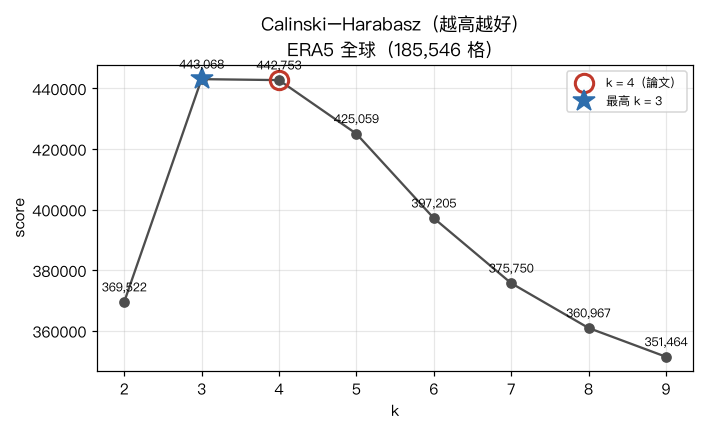

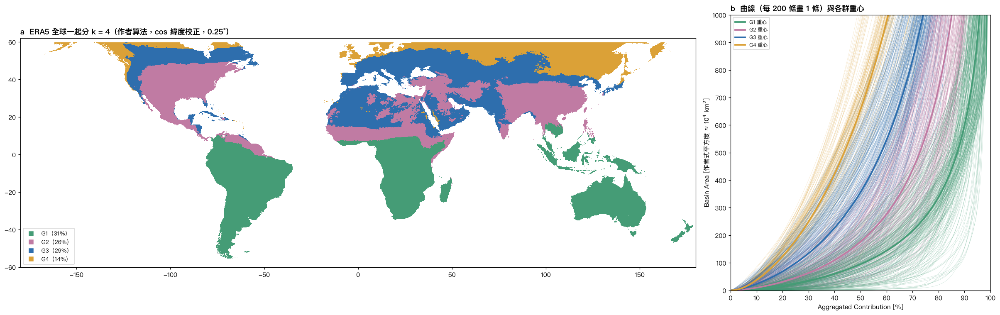

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(_KS, g8_ch, "o-", c="0.3")
ax.plot(4, g8_ch[2], "o", ms=12, mfc="none", mec="#C0392B", mew=2, label="k = 4（論文）")
ax.plot(g8_best, g8_ch.max(), "*", ms=15, c="#2E6EAD", label=f"最高 k = {g8_best}")
for k, v in zip(_KS, g8_ch):
    ax.annotate(f"{v:,.0f}", (k, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xticks(_KS); ax.set_xlabel("k"); ax.set_ylabel("score")
ax.set_title(f"Calinski–Harabasz（越高越好）\nERA5 全球（{gl_n:,} 格）"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_CH_ERA5_global.png", dpi=200, bbox_inches="tight"); plt.show()

fig, (axa, axb) = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [2.6, 1]})
axa.pcolormesh(_glon, _glat, e5_grid(g8_group, np.ones(gl_n, bool)), cmap=gg_cmap, norm=gg_norm, shading="nearest")
axa.set_aspect("equal"); axa.set_xlim(-180, 180); axa.set_ylim(-60, 62)
for g in range(4):
    axa.plot([], [], "s", c=GG_COLORS[g], label=f"G{g+1}（{(g8_group == g).mean()*100:.0f}%）")
axa.legend(loc="lower left", fontsize=9)
axa.set_title("a  ERA5 全球一起分 k = 4（作者算法，cos 緯度校正，0.25°）", loc="left", fontweight="bold")
_xc = gl_X[gg_idx100]
for g in [3, 2, 1, 0]:
    sel = np.nonzero(g8_group == g)[0][::200]
    axb.add_collection(LineCollection([np.column_stack([_xc, f]) for f in gl_feat[sel]], colors=GG_COLORS[g], linewidths=0.4, alpha=0.3))
for g in range(4):
    axb.plot(_xc, gl_feat[g8_group == g].mean(0), c=GG_COLORS[g], lw=2.5, label=f"G{g+1} 重心")
axb.set_xlim(0, 100); axb.set_ylim(0, 1000)
axb.set_xticks(range(0, 101, 10)); axb.set_yticks(range(0, 1001, 100))
axb.set_xlabel("Aggregated Contribution [%]"); axb.set_ylabel("Basin Area [作者式平方度 ≈ 10$^4$ km$^2$]")
axb.legend(loc="upper left", fontsize=8)
axb.set_title("b  曲線（每 200 條畫 1 條）與各群重心", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig2_ERA5_global.png", dpi=200, bbox_inches="tight"); plt.show()

### 8 小結

- **CH**（全部 185,546 格）：k = 3 最高（443,068），k = 4 幾乎一樣（442,753，99.9%），之後一路下降。
- **四群**：G1 30.9%、G2 25.7%、G3 29.0%、G4 14.4%；重心平均面積 230 / 536 / 848 / 1,247 作者式平方度；轉折點中位數 83.1 / 60.2 / 34.0 / 7.7%，**從 G1 到 G4 遞減**，順序和論文一樣（論文 95 / 69 / 48 / 36）。
- **地圖**：南半球陸地（南美、赤道以南的非洲、澳洲、紐西蘭、印尼）幾乎全是 G1；G2 是北半球的溫暖濕潤區（美國中東部、墨西哥、中美洲、薩赫爾到東非、中國南部、中南半島、印度南部）；G3 是北非與中東的乾燥帶、歐洲、中亞、加拿大與美國西部；G4 是高緯度的西伯利亞、阿拉斯加和北加拿大。
- **各洲落在哪一群**：南美 92.9% 是 G1、大洋洲 100% 是 G1；北美主要是 G2 / G3；歐洲 70% 是 G3；非洲分在 G1 / G2 / G3；亞洲四群都有。
- **和第 7 節（各洲分開）比**：全球一起分群時，每一洲內部的差異都被全球尺度蓋過，南美、大洋洲幾乎只剩一群，看不到第 7 節裡各洲自己的四型結構。
- **和之前刪掉的全球版（沒有 cos 校正）比**：當時南美 86% 落在同一群，cos 校正後變成 92.9%，結論不變——全球分群主要反映「周圍有多少陸地可以當來源」和緯度帶（南半球大陸被海洋包圍 → G1；北半球高緯度大陸內部 → G4），而不是論文「沿空中河流的上下游位置」。

## 9. 用自己寫的 EOF 分析南美洲曲線

用 `Code/EOF.py`（自己寫的 EOF 程式）的 `EOF` 類別（sklearn PCA）找南美洲排水曲線的主要變化模態，之後再拿來幫曲線分類。這一節先看**前幾個 modes 能解釋多少變異**。

- **資料**：第 7.3 節南美洲 7 個 AR6 區域（NWS、NSA、SAM、NES、SWS、SES、SSA）的全部 0.25° 格點，共 24,734 條曲線；每條用第 7.1 節的 100 點特徵 `gl_feat`（作者算法內插、cos 緯度校正後的作者式平方度），也就是第 7.3 節 k-means 用的 `sa_feat`。
- **矩陣**：(24,734 條曲線 × 100 個 C 點)。對 `EOF.py` 來說，「時間」維 = 曲線，「空間」維 = 曲線上的 100 個點，所以用 `field="1D"`。
- **標準化**：`EOF.py` 要求輸入先標準化，每個 C 點（每一欄）各自減掉 24,734 條曲線的平均、再除以標準差。這樣 100 個點的權重一樣，不會只被面積很大的曲線尾端主導。
- **輸出**：`explained` 是每個 mode 解釋的變異比例；畫每個 mode 的解釋 %（長條）與累積 %（折線），看累積到 90% 需要幾個 modes。

南美洲曲線：24,734 條，每條 100 個點
EOF 形狀 (100, 100)，PC 形狀 (100, 24734)

mode   解釋 %   累積 %
   1    72.35    72.35
   2    19.97    92.32
   3     4.00    96.32
   4     1.87    98.19
   5     0.84    99.03
   6     0.41    99.44
   7     0.27    99.71
   8     0.13    99.84
   9     0.06    99.90
  10     0.04    99.94

累積解釋 ≥ 90% 需要前 2 個 modes（累積 92.32%）
累積解釋 ≥ 95% 需要前 3 個 modes
累積解釋 ≥ 99% 需要前 5 個 modes


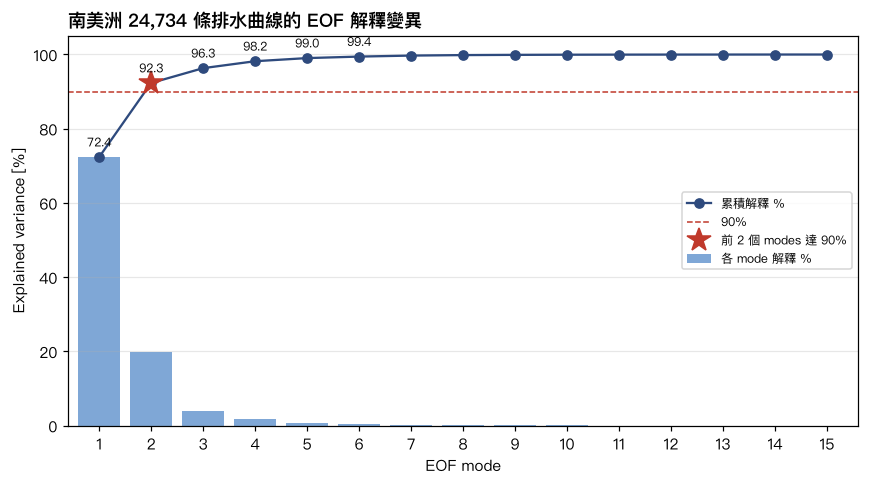

In [ ]:
from EOF import EOF                                      # Code/EOF.py（和筆記本同一個資料夾）

# (曲線數, 100)：南美 7 區全部 0.25° 格點的 100 點特徵（第 7.3 節的 sa_feat）
eof_X = sa_feat.astype(np.float64)
_sd = eof_X.std(0)
eof_Z = (eof_X - eof_X.mean(0)) / np.where(_sd > 0, _sd, 1)  # 每個 C 點標準化
eof_sa = EOF((eof_Z,), n_components=eof_Z.shape[1], field="1D")
eof_sa.get()

eof_pct = eof_sa.explained * 100
eof_cum = np.cumsum(eof_pct)
eof_n90 = int(np.argmax(eof_cum >= 90)) + 1
print(f"南美洲曲線：{eof_Z.shape[0]:,} 條，每條 {eof_Z.shape[1]} 個點")
print(f"EOF 形狀 {eof_sa.EOF.shape}，PC 形狀 {eof_sa.PC.shape}")
print("\nmode   解釋 %   累積 %")
for k in range(10):
    print(f"{k+1:4d}   {eof_pct[k]:6.2f}   {eof_cum[k]:6.2f}")
print(f"\n累積解釋 ≥ 90% 需要前 {eof_n90} 個 modes（累積 {eof_cum[eof_n90-1]:.2f}%）")
for p in (95, 99):
    print(f"累積解釋 ≥ {p}% 需要前 {int(np.argmax(eof_cum >= p)) + 1} 個 modes")

_nm = 15
_k = np.arange(1, _nm + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(_k, eof_pct[:_nm], color="#7FA7D6", label="各 mode 解釋 %")
ax.plot(_k, eof_cum[:_nm], "o-", c="#2E4A7D", label="累積解釋 %")
ax.axhline(90, ls="--", c="#C0392B", lw=1, label="90%")
ax.plot(eof_n90, eof_cum[eof_n90 - 1], "*", ms=16, c="#C0392B", label=f"前 {eof_n90} 個 modes 達 90%")
for k in range(min(_nm, 6)):
    ax.annotate(f"{eof_cum[k]:.1f}", (k + 1, eof_cum[k]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xticks(_k); ax.set_xlim(0.4, _nm + 0.6); ax.set_ylim(0, 105)
ax.set_xlabel("EOF mode"); ax.set_ylabel("Explained variance [%]")
ax.set_title(f"南美洲 {eof_Z.shape[0]:,} 條排水曲線的 EOF 解釋變異", loc="left", fontweight="bold")
ax.legend(loc="center right", fontsize=8); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_EOF_SA_explained.png", dpi=200, bbox_inches="tight"); plt.show()

### 9.1 前兩個 EOF 畫在地圖上

第 9 節把「曲線」當成時間維、「曲線上的 100 個 C 點」當成空間維，所以：

- **EOF1、EOF2** 本身是長度 100 的向量，代表**曲線形狀的變化型態**（沿著 C = 0–100% 的哪一段變大或變小），畫成對 C 的曲線（左欄）。
- 每條曲線（每個 0.25° 格點）在這兩個 EOF 上的投影是 **PC1、PC2**，這才是有經緯度的量，畫在南美洲地圖上（右欄）。
- 某格點的 PC 為正，代表它的曲線（標準化後）在 EOF 為正的那一段比南美平均大；PC 為負則相反。EOF 的正負號本身是任意的，EOF 和 PC 一起翻號結果相同。
- 地圖色階用 PC 的第 1–99 百分位對稱截斷，避免少數極端值把顏色壓扁。

PC1：範圍 -13.5 ~ 60.3，標準差 8.51
PC2：範圍 -9.7 ~ 27.7，標準差 4.47


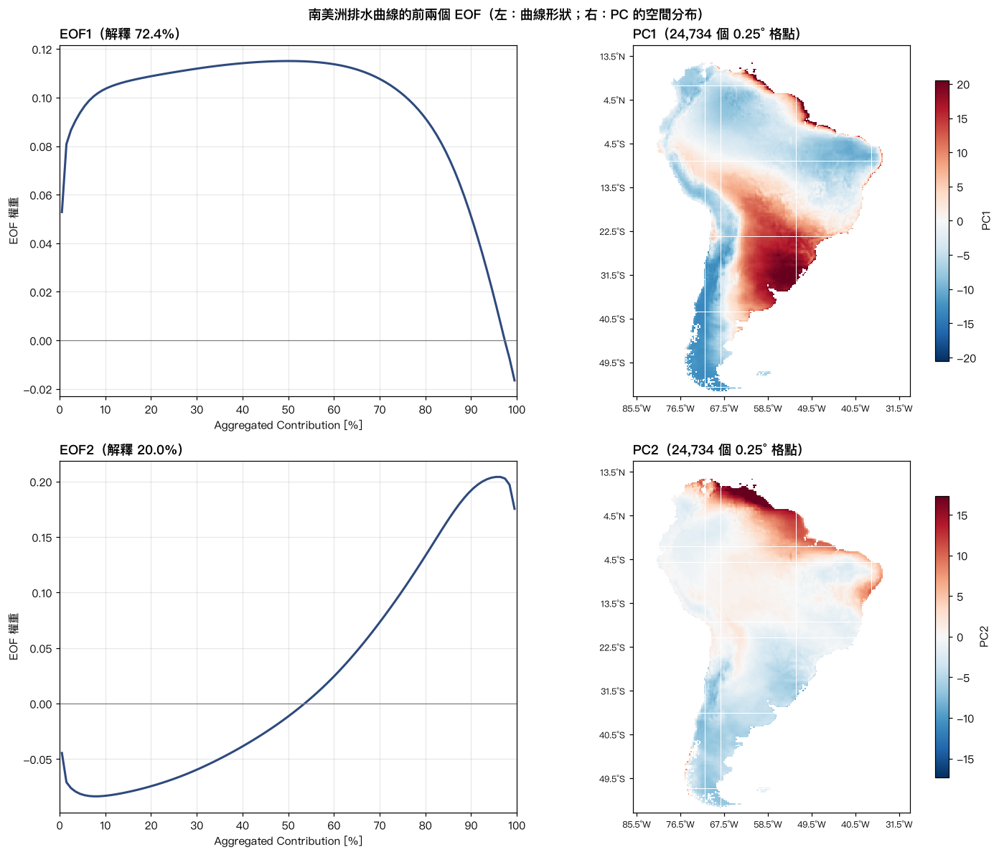

In [ ]:
_xc = gl_X[gg_idx100]                                   # 100 個點對應的 C [%]
_lat, _lon = gl_lat[sa_i], gl_lon[sa_i]
fig, axs = plt.subplots(2, 2, figsize=(13, 11), gridspec_kw={"width_ratios": [1, 1.1]})
for m in range(2):
    axe, axm = axs[m]
    axe.plot(_xc, eof_sa.EOF[m], c="#2E4A7D", lw=2)
    axe.axhline(0, c="0.5", lw=0.8)
    axe.set_xlim(0, 100); axe.set_xticks(range(0, 101, 10))
    axe.set_xlabel("Aggregated Contribution [%]"); axe.set_ylabel("EOF 權重")
    axe.set_title(f"EOF{m+1}（解釋 {eof_pct[m]:.1f}%）", loc="left", fontweight="bold"); axe.grid(alpha=0.3)

    pc = eof_sa.PC[m]
    v = np.nanpercentile(np.abs(pc), 99)
    sc = axm.scatter(_lon, _lat, c=pc, s=1.2, marker="s", cmap="RdBu_r", vmin=-v, vmax=v, linewidths=0)
    e5_mapax(axm, f"PC{m+1}（{eof_Z.shape[0]:,} 個 0.25° 格點）")
    plt.colorbar(sc, ax=axm, shrink=0.8, label=f"PC{m+1}")
    print(f"PC{m+1}：範圍 {pc.min():.1f} ~ {pc.max():.1f}，標準差 {pc.std():.2f}")
fig.suptitle("南美洲排水曲線的前兩個 EOF（左：曲線形狀；右：PC 的空間分布）", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_EOF_SA_EOF12_map.png", dpi=200, bbox_inches="tight"); plt.show()

### 9.2 EOF 怎麼「修改」平均曲線

把 EOF 想成一個**修改模板**，疊加在南美洲的平均曲線上：

$$\text{曲線} \approx \overline{A}(C) + \sigma(C)\,\big[\,PC_1\,\text{EOF}_1(C) + PC_2\,\text{EOF}_2(C) + \dots\big]$$

$\overline{A}$、$\sigma$ 是第 9 節標準化用的每個 C 點平均與標準差，乘回去就回到原始單位（作者式平方度）。下面每個 EOF 各畫一張：

- 黑線：南美 24,734 條曲線的平均。
- 彩色實線：只用這一個 EOF，PC 取 ±1、±2 個標準差時的曲線（紅 = 正、藍 = 負）。
- 細虛線：PC 最接近 +2σ、−2σ 的各 3 個實際格點的曲線，用來驗證模板是不是真的長這樣（其他 EOF 的部分沒有扣掉，所以不會完全重合）。

PC1 標準差 σ = 8.51
PC2 標準差 σ = 4.47


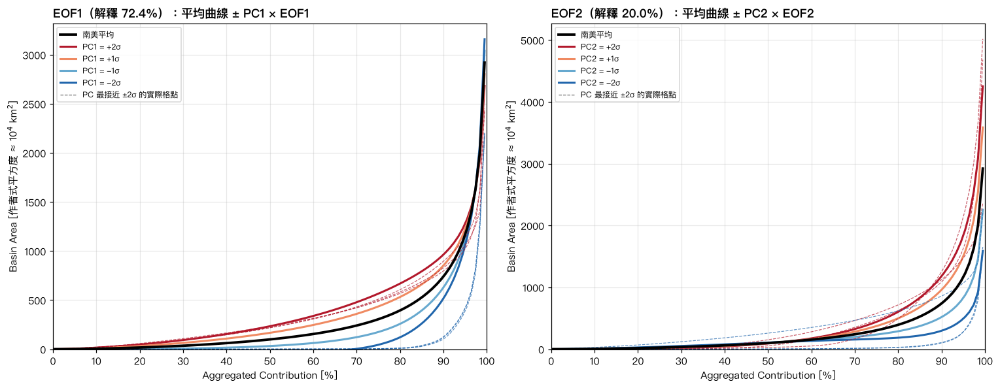

In [ ]:
_mu, _sdv = eof_X.mean(0), np.where(_sd > 0, _sd, 1)
_xc = gl_X[gg_idx100]
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for m, ax in enumerate(axs):
    pc = eof_sa.PC[m]; s = pc.std()
    ax.plot(_xc, _mu, c="k", lw=2.5, label="南美平均", zorder=5)
    for n, c in [(2, "#B2182B"), (1, "#EF8A62"), (-1, "#67A9CF"), (-2, "#2166AC")]:
        ax.plot(_xc, _mu + _sdv * n * s * eof_sa.EOF[m], c=c, lw=2, label=f"PC{m+1} = {n:+d}σ")
    for n, c in [(2, "#B2182B"), (-2, "#2166AC")]:
        for k in np.argsort(np.abs(pc - n * s))[:3]:
            ax.plot(_xc, eof_X[k], c=c, lw=0.8, ls="--", alpha=0.7)
    ax.plot([], [], c="0.4", lw=0.8, ls="--", label="PC 最接近 ±2σ 的實際格點")
    ax.set_xlim(0, 100); ax.set_ylim(bottom=0); ax.set_xticks(range(0, 101, 10))
    ax.set_xlabel("Aggregated Contribution [%]"); ax.set_ylabel("Basin Area [作者式平方度 ≈ 10$^4$ km$^2$]")
    ax.set_title(f"EOF{m+1}（解釋 {eof_pct[m]:.1f}%）：平均曲線 ± PC{m+1} × EOF{m+1}", loc="left", fontweight="bold")
    ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
    print(f"PC{m+1} 標準差 σ = {s:.2f}")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_EOF_SA_mean_pm.png", dpi=200, bbox_inches="tight"); plt.show()

### 9.3 EOF-based clustering：南美洲 PC1、PC2 → k-means 4 群

先用 EOF 降維，再分群（又叫 Functional PCA + K-means）：

1. **降維**：每條曲線原本是 100 點特徵（第 9 節），前 2 個 modes 已經解釋 92.3%（> 90%），所以只保留 PC1、PC2。
2. **分群**：每個 0.25° 格點的 (PC1, PC2) 當成新的 2 維特徵，放進 k-means 分 4 群。PC 不再另外標準化：PC1 的變異本來就比 PC2 大，保留原始尺度等於在「標準化曲線空間」裡量距離，只是丟掉其餘 7.7% 的變異。
3. 和第 7.3 節一樣：CH 測 k = 2–9（`n_init=10, random_state=0`），k-means 4 群（`n_init=50, random_state=0`），依 C = 50% 的面積 A50 中位數由小到大命名 G1–G4。
4. **比較**：(1) 和第 7.3 節用 100 點特徵直接分群的結果比；(2) 和論文分群比（0.25° 逐格，以及多數決合併回 1.5°）。

In [ ]:
eof_F = eof_sa.PC[:2].T                                   # (24,734, 2)：PC1、PC2
eof_ch = np.array([calinski_harabasz_score(eof_F, KMeans(k, n_init=10, random_state=0).fit_predict(eof_F)) for k in _KS])
eof_best = _KS[np.argmax(eof_ch)]
print("CH（PC1, PC2）：" + "  ".join(f"k={k}:{v:,.0f}" for k, v in zip(_KS, eof_ch)) + f"\nCH 最高 k = {eof_best}；k = 4 是最高分的 {eof_ch[2] / eof_ch.max() * 100:.1f}%")

_km = KMeans(n_clusters=4, n_init=50, random_state=0).fit(eof_F)
_med = [np.median(sa_a50[_km.labels_ == g]) for g in range(4)]
_rank = np.empty(4, int); _rank[np.argsort(_med)] = np.arange(4)
eof_group = _rank[_km.labels_]
eof_cent = np.empty((4, 2)); eof_cent[_rank] = _km.cluster_centers_
gl_eofgroup = np.full(gl_n, -1); gl_eofgroup[sa_i] = eof_group

print("\n        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）     重心 (PC1, PC2)")
for g in range(4):
    m = eof_group == g; t = gl_tp[sa_i][m]
    print(f"G{g+1}   {m.sum():6d} ({m.mean()*100:4.1f}%)      {np.median(sa_a50[m]):6.0f}                  "
          f"{np.nanmedian(t):5.1f} ({np.nanpercentile(t, 25):.1f}–{np.nanpercentile(t, 75):.1f})      ({eof_cent[g, 0]:6.1f}, {eof_cent[g, 1]:5.1f})")

print(f"\n和第 7.3 節（100 點特徵直接分群）比：同名一致 {np.mean(eof_group == sa_group)*100:.1f}%，最佳標籤對應 {gg_agree(eof_group, sa_group)*100:.1f}%")
cm7 = np.array([[np.sum((sa_group == a) & (eof_group == b)) for b in range(4)] for a in range(4)])
print("  混淆矩陣（列 = 7.3 的 G，欄 = EOF 的 G）")
for a in range(4):
    print(f"  7.3 G{a+1}" + "".join(f"{v:8d}" for v in cm7[a]))

_m = gl_sa & (gl_paper >= 0)
print(f"\n和論文比 (1) 0.25° 逐格（{_m.sum()} 格）：同名一致 {np.mean(gl_eofgroup[_m] == gl_paper[_m])*100:.1f}%，最佳標籤對應 {gg_agree(gl_eofgroup[_m], gl_paper[_m])*100:.1f}%")
eof_vote = e5_vote(gl_eofgroup, gl_sa); _v = eof_vote >= 0
print(f"和論文比 (2) 多數決合併到 1.5°（{_v.sum()} 格）：同名一致 {np.mean(eof_vote[_v] == gg_group[_v])*100:.1f}%，最佳標籤對應 {gg_agree(eof_vote[_v], gg_group[_v])*100:.1f}%")
cmp = np.array([[np.sum((gl_paper[_m] == a) & (gl_eofgroup[_m] == b)) for b in range(4)] for a in range(4)])
print("  混淆矩陣 0.25°（列 = 論文 G，欄 = EOF 的 G）")
for a in range(4):
    print(f"  論文G{a+1}" + "".join(f"{v:8d}" for v in cmp[a]))
print("\n轉折點中位數：" + "  ".join(f"G{g+1} {np.nanmedian(gl_tp[sa_i][eof_group == g]):.1f}%" for g in range(4)) + f"   （論文 {' / '.join(map(str, paper))}）")

CH（PC1, PC2）：k=2:61,048  k=3:77,528  k=4:85,438  k=5:101,014  k=6:109,184  k=7:121,386  k=8:135,864  k=9:148,444
CH 最高 k = 9；k = 4 是最高分的 57.6%

        格數（比例）           A50 中位數（等效 deg²）   轉折點中位數（Q1–Q3）     重心 (PC1, PC2)
G1     6130 (24.8%)          27                   76.0 (69.4–81.1)      (  -9.1,  -9.1)
G2     9077 (36.7%)          71                   79.2 (63.9–85.8)      (  -3.2,  -3.2)
G3     5452 (22.0%)         136                   84.8 (23.9–91.6)      (   4.1,   4.1)
G4     4075 (16.5%)         212                   95.4 (5.7–96.6)      (  15.2,  15.2)

和第 7.3 節（100 點特徵直接分群）比：同名一致 33.0%，最佳標籤對應 52.0%
  混淆矩陣（列 = 7.3 的 G，欄 = EOF 的 G）
  7.3 G1    2991     592     236       0
  7.3 G2     230     983     596     247
  7.3 G3    2831    5351     354       0
  7.3 G4      78    2151    4266    3828

和論文比 (1) 0.25° 逐格（24020 格）：同名一致 56.7%，最佳標籤對應 56.7%
和論文比 (2) 多數決合併到 1.5°（713 格）：同名一致 56.4%，最佳標籤對應 56.4%
  混淆矩陣 0.25°（列 = 論文 G，欄 = EOF 的 G）
  論文G1    3118    2067     635     243
  論文G2 

IndexError: index 1 is out of bounds for axis 1 with size 1

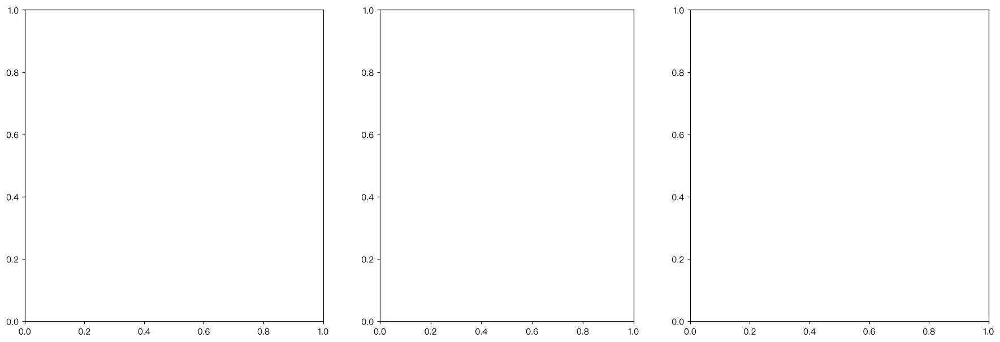

In [39]:
fig, axs = plt.subplots(1, 3, figsize=(20, 6.5), gridspec_kw={"width_ratios": [1, 0.85, 1]})
# a：PC1–PC2 散布
ax = axs[0]
_sel = np.arange(len(sa_i))[::5]
ax.scatter(eof_F[_sel, 0], eof_F[_sel, 1], c=[GG_COLORS[g] for g in eof_group[_sel]], s=2, alpha=0.5, linewidths=0)
ax.scatter(eof_cent[:, 0], eof_cent[:, 1], c=GG_COLORS[:4], s=180, marker="X", edgecolors="k", linewidths=1, zorder=5)
for g in range(4):
    ax.plot([], [], "s", c=GG_COLORS[g], label=f"G{g+1}（{(eof_group == g).mean()*100:.0f}%）")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_xlabel(f"PC1（{eof_pct[0]:.1f}%）"); ax.set_ylabel(f"PC2（{eof_pct[1]:.1f}%）")
ax.set_title("a  PC1–PC2 空間的 k-means（每 5 點畫 1 點，X = 重心）", loc="left", fontweight="bold")
# b：地圖
ax = axs[1]
_la, _lo = gl_lat[sa_i], gl_lon[sa_i]
_gla = np.arange(_la.min(), _la.max() + 0.125, 0.25); _glo = np.arange(_lo.min(), _lo.max() + 0.125, 0.25)
_G = np.full((_gla.size, _glo.size), np.nan)
_G[np.round((_la - _gla[0]) / 0.25).astype(int), np.round((_lo - _glo[0]) / 0.25).astype(int)] = eof_group
ax.pcolormesh(_glo, _gla, _G, cmap=gg_cmap, norm=gg_norm, shading="nearest")
e5_mapax(ax, "b  EOF-based 分群（0.25°）")
# c：曲線與重心
ax = axs[2]; _xc = gl_X[gg_idx100]
for g in [3, 2, 1, 0]:
    sel = np.nonzero(eof_group == g)[0][::10]
    ax.add_collection(LineCollection([np.column_stack([_xc, f]) for f in sa_feat[sel]], colors=GG_COLORS[g], linewidths=0.4, alpha=0.3))
for g in range(4):
    ax.plot(_xc, sa_feat[eof_group == g].mean(0), c=GG_COLORS[g], lw=2.5, label=f"G{g+1} 重心")
ax.set_xlim(0, 100); ax.set_ylim(0, 1000); ax.set_xticks(range(0, 101, 10)); ax.set_yticks(range(0, 1001, 100))
ax.set_xlabel("Aggregated Contribution [%]"); ax.set_ylabel("Basin Area [作者式平方度 ≈ 10$^4$ km$^2$]")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("c  曲線（每 10 條畫 1 條）與各群重心", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "Fig_EOF_SA_kmeans.png", dpi=200, bbox_inches="tight"); plt.show()

### 其他各洲與全球：同樣的 EOF 做法

和第 9–9.2 節南美洲**完全一樣的做法**，換成其他各洲與全球（第 8 節已經是「全球一起分群」，所以這裡接在第 9 節後面，編號 9.4–9.9）：

- **資料**：各洲用第 7 節同一套 AR6 區域定義的全部 0.25° 格點；全球用全部 185,546 格。每條曲線都是第 7.1 節的 100 點特徵 `gl_feat`（作者算法、cos 緯度校正後的作者式平方度）。
- **EOF**：每個 C 點各自用該區域的平均、標準差標準化，`EOF((Z,), n_components=100, field="1D")`。**各區域各自算 EOF**，所以不同洲的 EOF1、EOF2 形狀不一定一樣，PC 也不能跨洲直接比大小。
- **三張圖**：(a) 各 mode 解釋 % 與累積 %，標出達 90% 的 mode 數；(b) EOF1、EOF2 的曲線形狀與 PC1、PC2 地圖（色階用 |PC| 第 99 百分位對稱截斷）；(c) 平均曲線 ± 1σ、2σ 的 PC × EOF，細虛線是 PC 最接近 ±2σ 的各 3 個實際格點。
- 最後 9.10 把各區域（含南美洲）整理成一張總表。

In [ ]:
EOF_REGIONS = {"北美洲": ["NWN", "NEN", "WNA", "CNA", "ENA", "NCA", "SCA", "CAR"], "歐洲": ["NEU", "WCE", "EEU", "MED"],
               "非洲": ["SAH", "WAF", "CAF", "NEAF", "SEAF", "WSAF", "ESAF", "MDG"],
               "亞洲": ["WSB", "ESB", "RFE", "WCA", "ECA", "TIB", "EAS", "ARP", "SAS", "SEA"],
               "大洋洲": ["NAU", "CAU", "EAU", "SAU", "NZ"]}
eof_res = {"南美洲": dict(n=eof_Z.shape[0], pct=eof_pct, cum=eof_cum)}   # 給 9.9 總表用

def eof_region(name, mask, tag):
    idx = np.nonzero(mask)[0]
    X = gl_feat[idx].astype(np.float64)
    lat, lon = gl_lat[idx], gl_lon[idx]
    mu, sd = X.mean(0), X.std(0); sd = np.where(sd > 0, sd, 1)
    Z = (X - mu) / sd
    e = EOF((Z,), n_components=Z.shape[1], field="1D"); e.get()
    pct = e.explained * 100; cum = np.cumsum(pct)
    nk = {p: int(np.argmax(cum >= p)) + 1 for p in (90, 95, 99)}
    eof_res[name] = dict(n=len(idx), pct=pct, cum=cum)
    print(f"{name}：{len(idx):,} 條曲線")
    print("mode   解釋 %   累積 %")
    for k in range(6):
        print(f"{k+1:4d}   {pct[k]:6.2f}   {cum[k]:6.2f}")
    print("累積 ≥ 90% / 95% / 99% 需要 " + " / ".join(f"{nk[p]}" for p in (90, 95, 99)) + " 個 modes")

    # (a) 解釋變異
    nm = 15; kk = np.arange(1, nm + 1)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(kk, pct[:nm], color="#7FA7D6", label="各 mode 解釋 %")
    ax.plot(kk, cum[:nm], "o-", c="#2E4A7D", label="累積解釋 %")
    ax.axhline(90, ls="--", c="#C0392B", lw=1, label="90%")
    ax.plot(nk[90], cum[nk[90] - 1], "*", ms=16, c="#C0392B", label=f"前 {nk[90]} 個 modes 達 90%")
    for k in range(6):
        ax.annotate(f"{cum[k]:.1f}", (k + 1, cum[k]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
    ax.set_xticks(kk); ax.set_xlim(0.4, nm + 0.6); ax.set_ylim(0, 105)
    ax.set_xlabel("EOF mode"); ax.set_ylabel("Explained variance [%]")
    ax.set_title(f"{name} {len(idx):,} 條排水曲線的 EOF 解釋變異", loc="left", fontweight="bold")
    ax.legend(loc="center right", fontsize=8); ax.grid(alpha=0.3, axis="y")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"Fig_EOF_{tag}_explained.png", dpi=200, bbox_inches="tight"); plt.show()

    # (b) EOF 曲線 + PC 地圖
    xc = gl_X[gg_idx100]
    glat = np.arange(lat.min(), lat.max() + 0.125, 0.25); glon = np.arange(lon.min(), lon.max() + 0.125, 0.25)
    ii = np.round((lat - glat[0]) / 0.25).astype(int); jj = np.round((lon - glon[0]) / 0.25).astype(int)
    w = min(max((lon.max() - lon.min()) / (lat.max() - lat.min()), 0.8), 3)
    fig, axs = plt.subplots(2, 2, figsize=(6 + 5.5 * w, 11), gridspec_kw={"width_ratios": [1, w]})
    for m in range(2):
        axe, axm = axs[m]
        axe.plot(xc, e.EOF[m], c="#2E4A7D", lw=2); axe.axhline(0, c="0.5", lw=0.8)
        axe.set_xlim(0, 100); axe.set_xticks(range(0, 101, 10))
        axe.set_xlabel("Aggregated Contribution [%]"); axe.set_ylabel("EOF 權重")
        axe.set_title(f"EOF{m+1}（解釋 {pct[m]:.1f}%）", loc="left", fontweight="bold"); axe.grid(alpha=0.3)
        G = np.full((glat.size, glon.size), np.nan); G[ii, jj] = e.PC[m]
        v = np.nanpercentile(np.abs(e.PC[m]), 99)
        pm = axm.pcolormesh(glon, glat, G, cmap="RdBu_r", vmin=-v, vmax=v, shading="nearest")
        axm.set_aspect("equal"); axm.set_xlabel("經度"); axm.set_ylabel("緯度")
        axm.set_title(f"PC{m+1}（{len(idx):,} 個 0.25° 格點）", loc="left", fontweight="bold")
        plt.colorbar(pm, ax=axm, shrink=0.8, label=f"PC{m+1}")
    fig.suptitle(f"{name}排水曲線的前兩個 EOF（左：曲線形狀；右：PC 的空間分布）", fontweight="bold")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"Fig_EOF_{tag}_EOF12_map.png", dpi=200, bbox_inches="tight"); plt.show()

    # (c) 平均曲線 ± PC × EOF
    fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
    for m, ax in enumerate(axs):
        pc = e.PC[m]; s = pc.std()
        ax.plot(xc, mu, c="k", lw=2.5, label=f"{name}平均", zorder=5)
        for n, c in [(2, "#B2182B"), (1, "#EF8A62"), (-1, "#67A9CF"), (-2, "#2166AC")]:
            ax.plot(xc, mu + sd * n * s * e.EOF[m], c=c, lw=2, label=f"PC{m+1} = {n:+d}σ")
        for n, c in [(2, "#B2182B"), (-2, "#2166AC")]:
            for k in np.argsort(np.abs(pc - n * s))[:3]:
                ax.plot(xc, X[k], c=c, lw=0.8, ls="--", alpha=0.7)
        ax.plot([], [], c="0.4", lw=0.8, ls="--", label="PC 最接近 ±2σ 的實際格點")
        ax.set_xlim(0, 100); ax.set_ylim(bottom=0); ax.set_xticks(range(0, 101, 10))
        ax.set_xlabel("Aggregated Contribution [%]"); ax.set_ylabel("Basin Area [作者式平方度 ≈ 10$^4$ km$^2$]")
        ax.set_title(f"EOF{m+1}（解釋 {pct[m]:.1f}%）：平均曲線 ± PC{m+1} × EOF{m+1}", loc="left", fontweight="bold")
        ax.legend(loc="upper left", fontsize=8); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(FIG_DIR / f"Fig_EOF_{tag}_mean_pm.png", dpi=200, bbox_inches="tight"); plt.show()
    return e

### 9.4 北美洲

北美洲：30,506 條曲線
mode   解釋 %   累積 %
   1    77.24    77.24
   2    17.77    95.01
   3     2.34    97.35
   4     1.31    98.67
   5     0.71    99.38
   6     0.35    99.73
累積 ≥ 90% / 95% / 99% 需要 2 / 2 / 5 個 modes


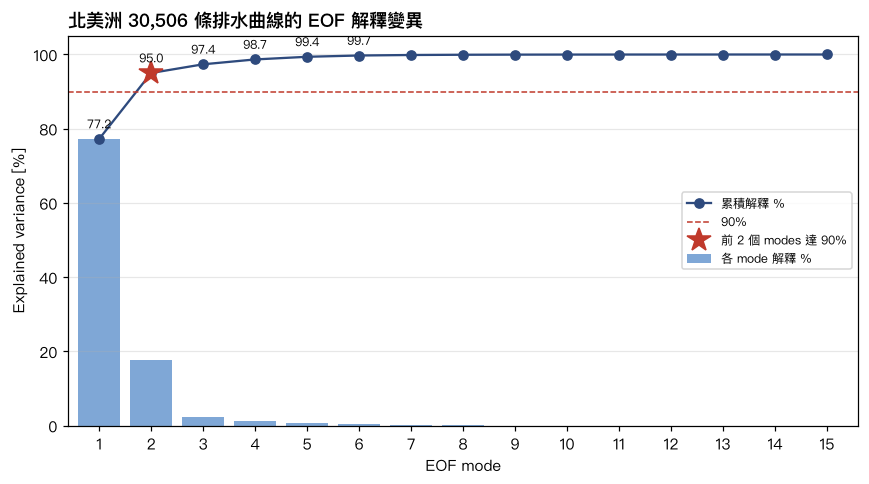

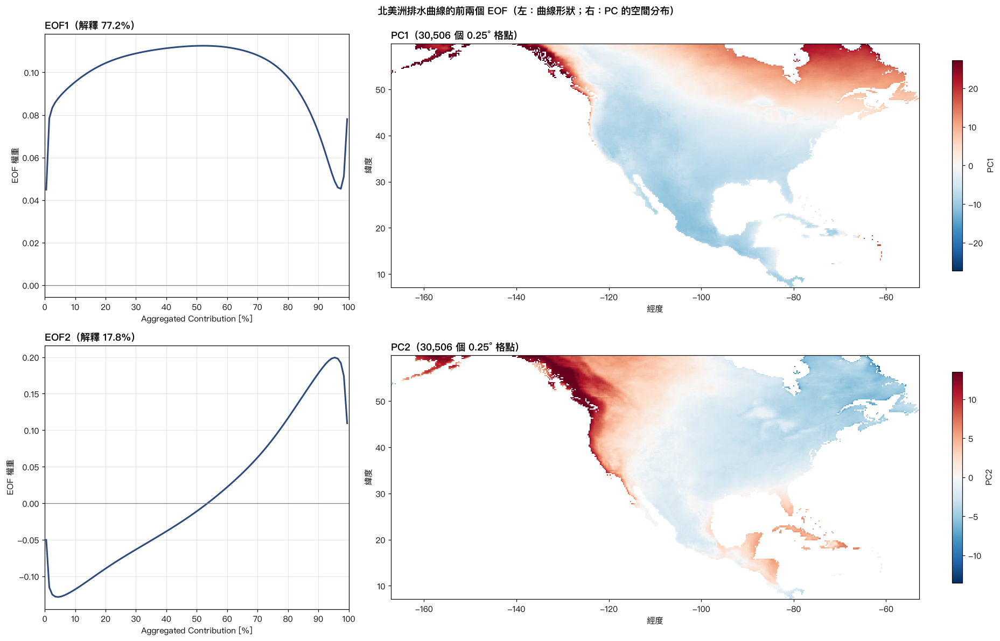

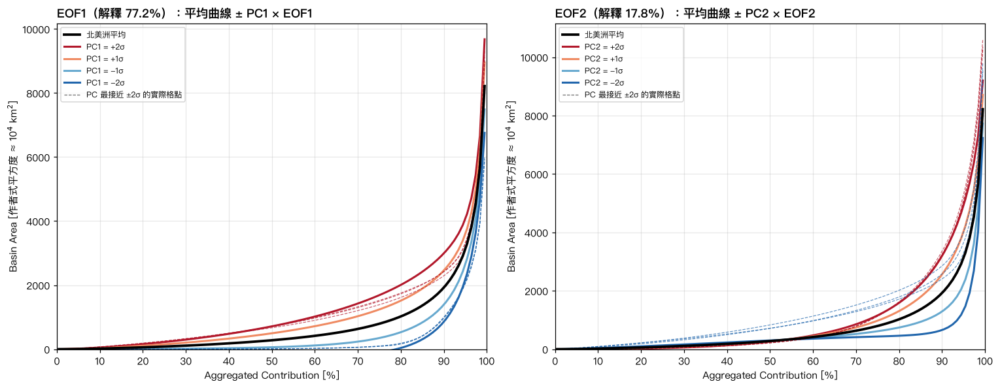

In [ ]:
eof_NAm = eof_region("北美洲", np.isin(gl_rg, EOF_REGIONS["北美洲"]), "NAm")

### 9.5 歐洲

歐洲：19,865 條曲線
mode   解釋 %   累積 %
   1    75.99    75.99
   2    16.59    92.58
   3     3.15    95.73
   4     2.46    98.19
   5     0.77    98.96
   6     0.46    99.42
累積 ≥ 90% / 95% / 99% 需要 2 / 3 / 6 個 modes


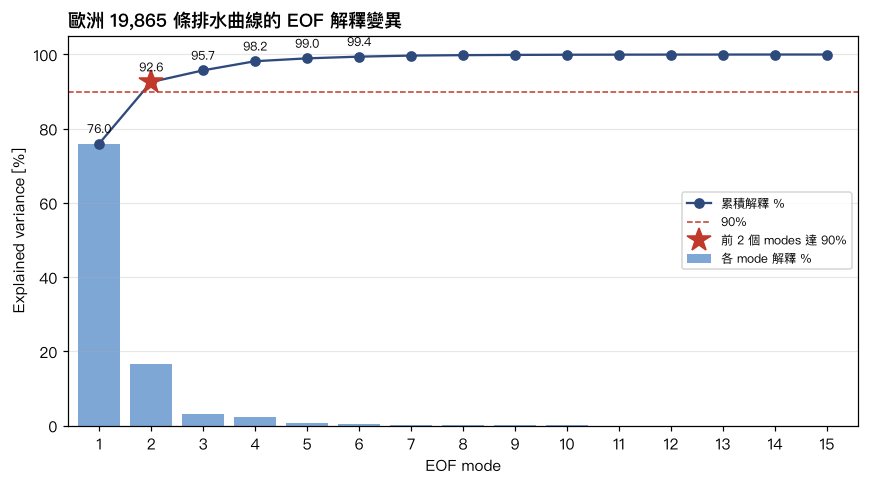

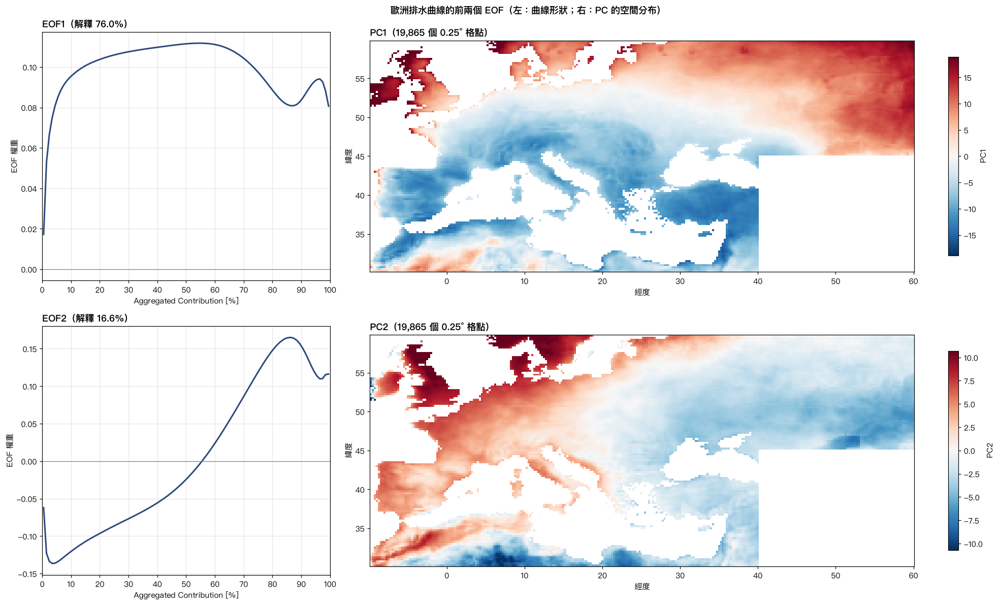

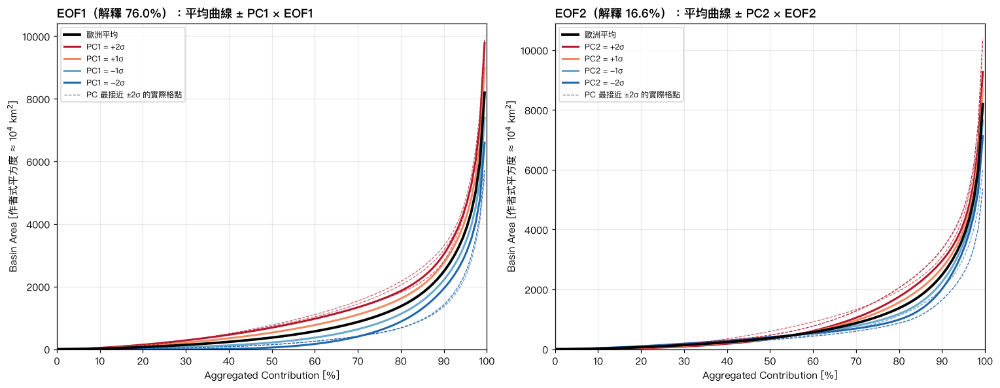

In [ ]:
eof_EU = eof_region("歐洲", np.isin(gl_rg, EOF_REGIONS["歐洲"]), "EU")

### 9.6 非洲

非洲：38,432 條曲線
mode   解釋 %   累積 %
   1    92.12    92.12
   2     5.38    97.50
   3     1.55    99.05
   4     0.61    99.66
   5     0.17    99.83
   6     0.07    99.91
累積 ≥ 90% / 95% / 99% 需要 1 / 2 / 3 個 modes


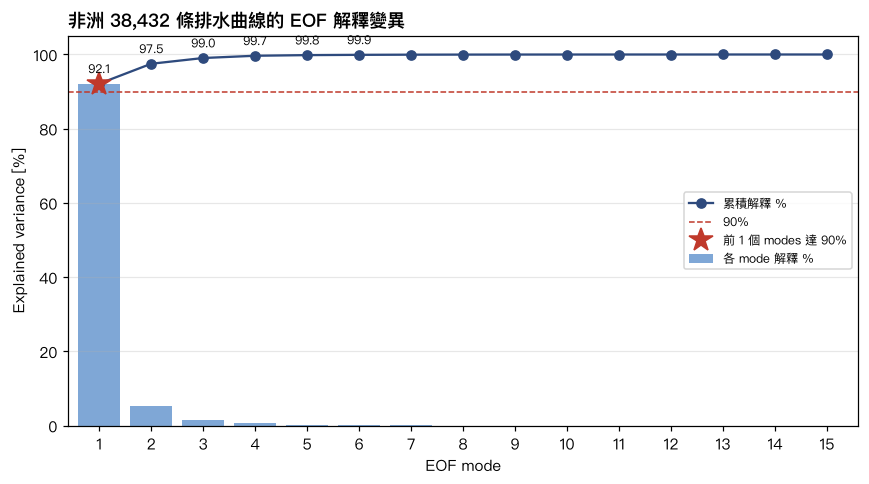

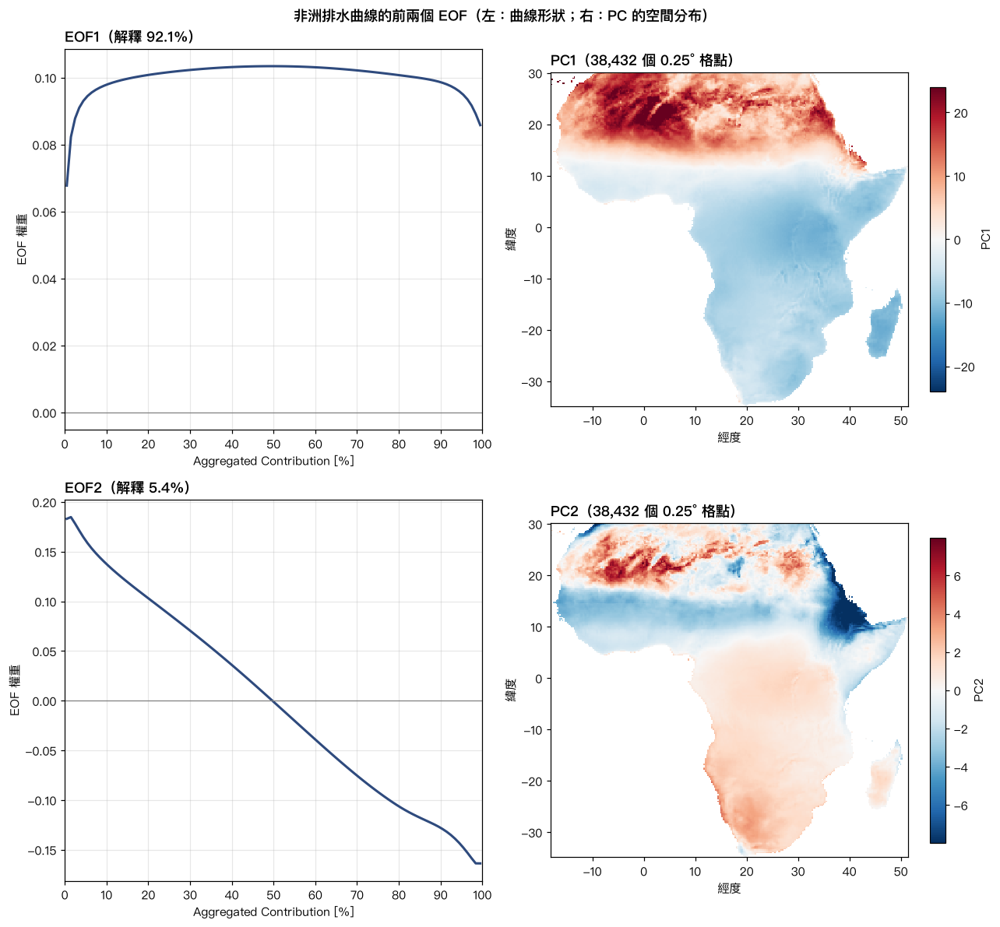

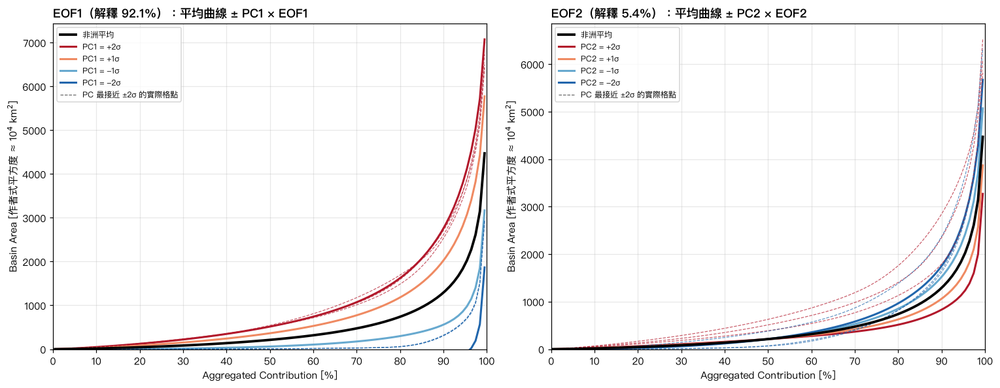

In [ ]:
eof_AF = eof_region("非洲", np.isin(gl_rg, EOF_REGIONS["非洲"]), "AF")

### 9.7 亞洲

亞洲：60,348 條曲線
mode   解釋 %   累積 %
   1    91.22    91.22
   2     4.62    95.84
   3     2.55    98.39
   4     0.71    99.10
   5     0.50    99.60
   6     0.20    99.80
累積 ≥ 90% / 95% / 99% 需要 1 / 2 / 4 個 modes


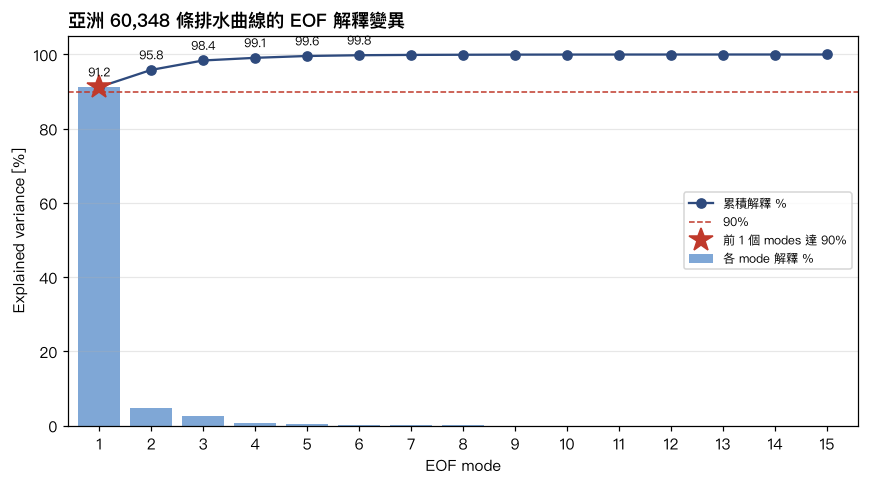

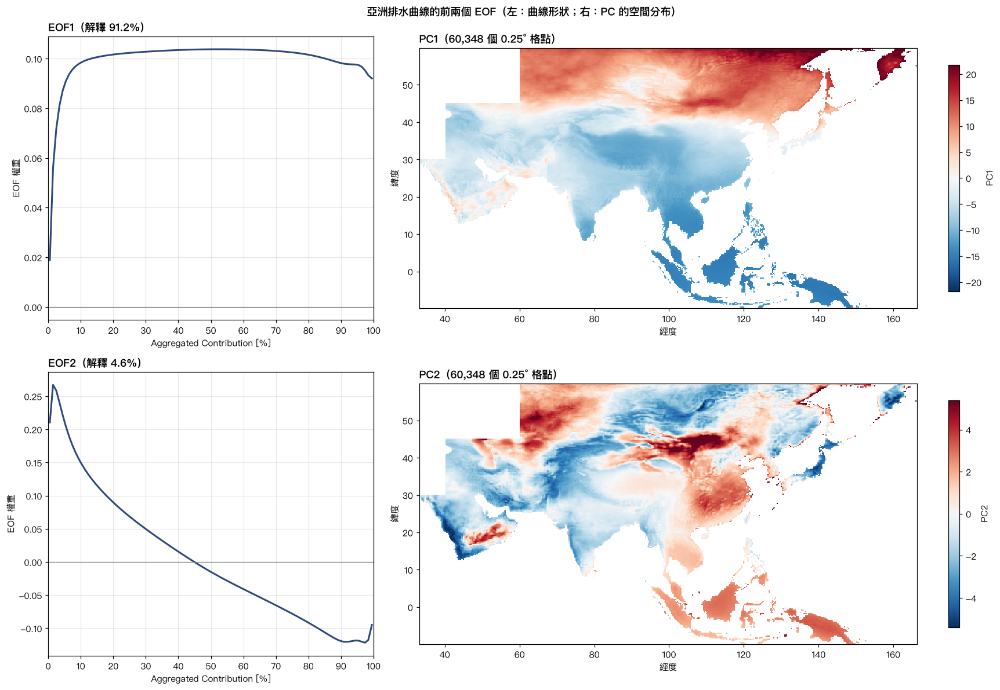

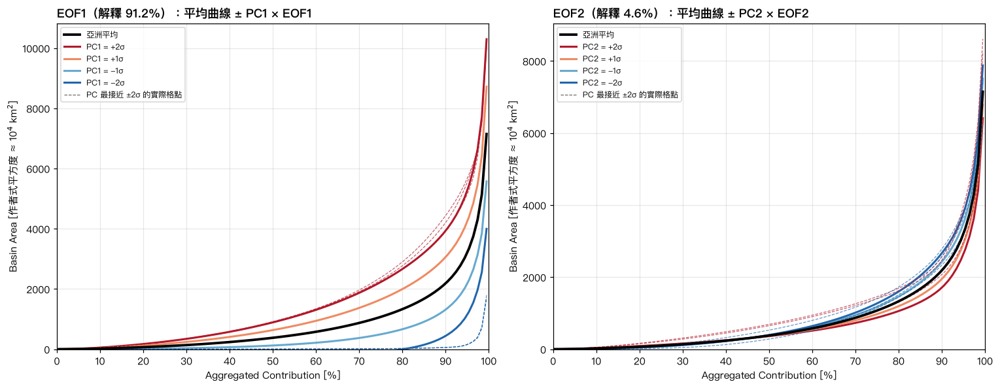

In [ ]:
eof_AS = eof_region("亞洲", np.isin(gl_rg, EOF_REGIONS["亞洲"]), "AS")

### 9.8 大洋洲

大洋洲：11,661 條曲線
mode   解釋 %   累積 %
   1    76.12    76.12
   2    15.57    91.69
   3     4.85    96.54
   4     1.45    97.98
   5     0.99    98.97
   6     0.51    99.48
累積 ≥ 90% / 95% / 99% 需要 2 / 3 / 6 個 modes


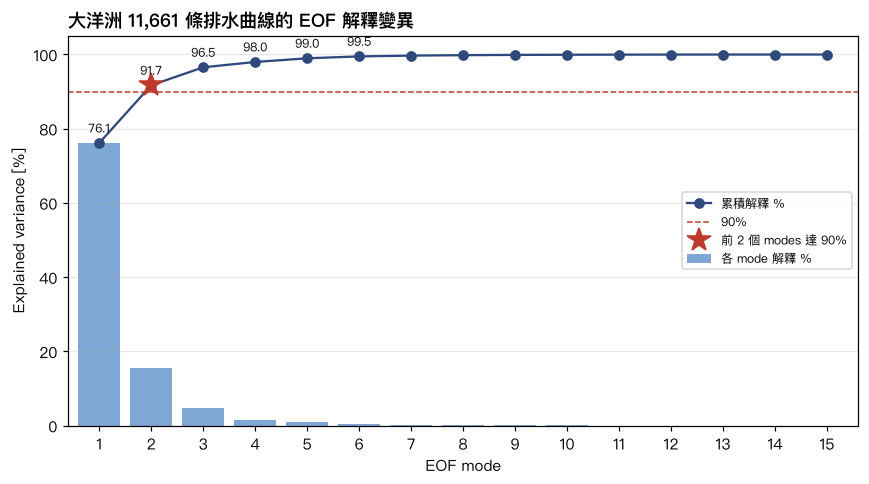

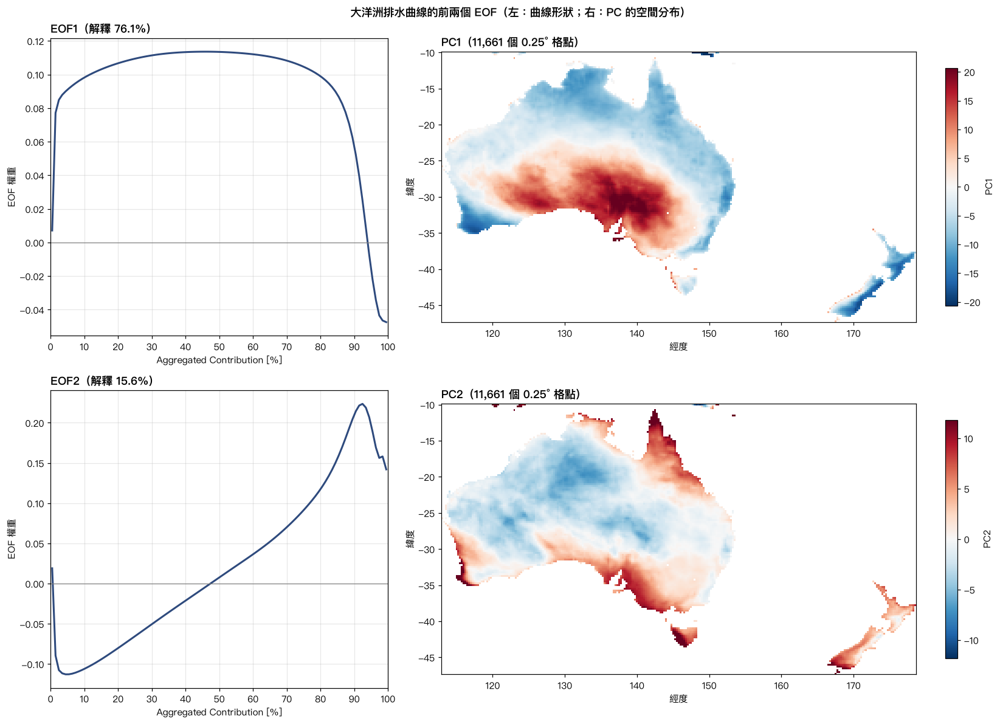

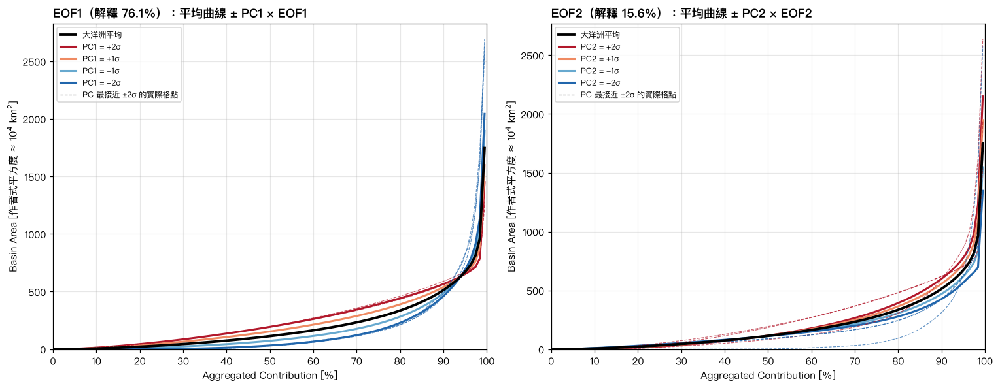

In [ ]:
eof_OC = eof_region("大洋洲", np.isin(gl_rg, EOF_REGIONS["大洋洲"]), "OC")

### 9.9 全球（全部 185,546 個陸地格點一起算 EOF）

全球：185,546 條曲線
mode   解釋 %   累積 %
   1    86.50    86.50
   2     8.51    95.01
   3     2.95    97.96
   4     1.20    99.16
   5     0.43    99.59
   6     0.21    99.79
累積 ≥ 90% / 95% / 99% 需要 2 / 2 / 4 個 modes


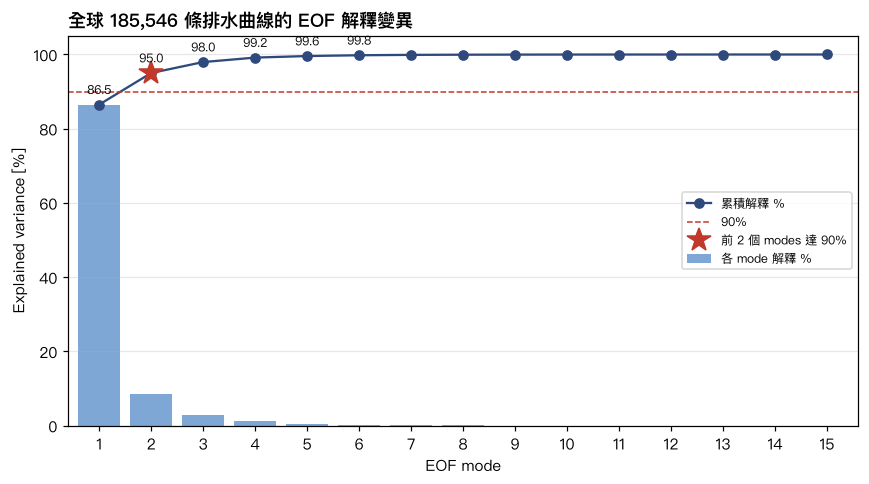

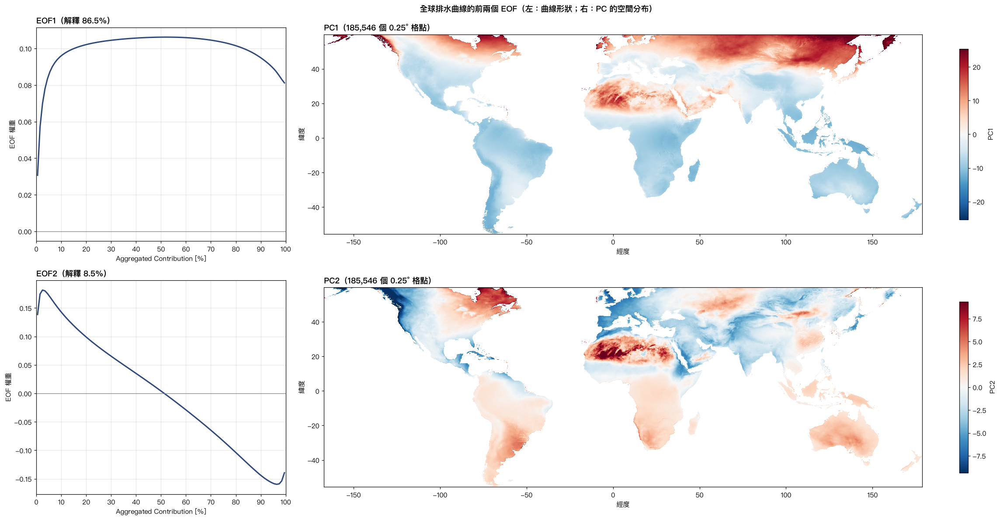

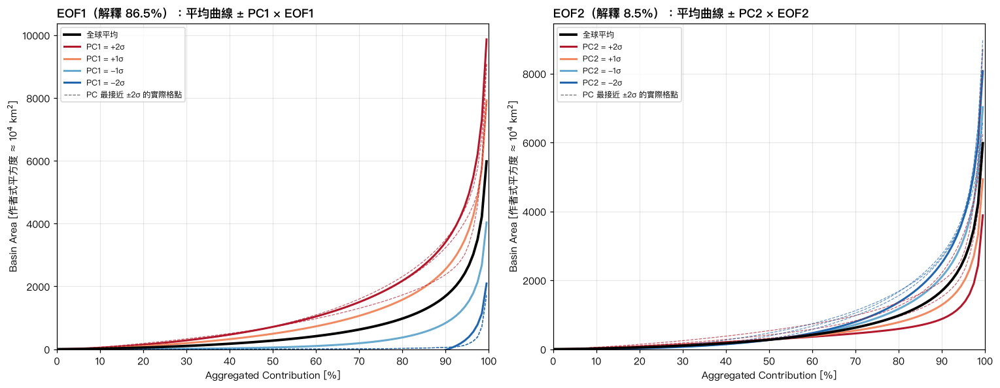

In [ ]:
eof_GL = eof_region("全球", np.ones(gl_n, bool), "global")

### 9.10 各區域 EOF 總表

In [ ]:
print(f"{'區域':<6}{'曲線數':>9}{'EOF1 %':>9}{'EOF2 %':>9}{'EOF3 %':>9}{'前2累積 %':>11}   達 90% / 95% / 99% 的 mode 數")
for n in ["南美洲", "北美洲", "歐洲", "非洲", "亞洲", "大洋洲", "全球"]:
    r = eof_res[n]; c = r["cum"]
    nk = [int(np.argmax(c >= p)) + 1 for p in (90, 95, 99)]
    print(f"{n:<6}{r['n']:>9,}{r['pct'][0]:>9.1f}{r['pct'][1]:>9.1f}{r['pct'][2]:>9.1f}{c[1]:>11.1f}   " + " / ".join(map(str, nk)))

區域          曲線數   EOF1 %   EOF2 %   EOF3 %     前2累積 %   達 90% / 95% / 99% 的 mode 數
南美洲      24,734     72.4     20.0      4.0       92.3   2 / 3 / 5
北美洲      30,506     77.2     17.8      2.3       95.0   2 / 2 / 5
歐洲       19,865     76.0     16.6      3.1       92.6   2 / 3 / 6
非洲       38,432     92.1      5.4      1.5       97.5   1 / 2 / 3
亞洲       60,348     91.2      4.6      2.5       95.8   1 / 2 / 4
大洋洲      11,661     76.1     15.6      4.8       91.7   2 / 3 / 6
全球      185,546     86.5      8.5      3.0       95.0   2 / 2 / 4
